# Faster R-CNN: GIoU, 6 epochs, rotating offsets and photometric/resolution augmentation (pipeline, tuned)

## Overview

Parent run: `faster-rcnn-giou` (T3, run `dmnk1304/faster-rcnn-giou`): torchvision `fasterrcnn_resnet50_fpn_v2`, COCO weights, 1280 px, anchor sizes 16–256 (inherited from T1 `faster-rcnn-small-anchors`), GIoU box loss in the RoI head with weight 10.0, 12 epochs, every 5th training frame (offset 0) in every epoch, horizontal flip as the only augmentation. T3 on full val: mAP@500 0.2371, AP75 0.2016, AP_small 0.1312, 241.8 ms/img, 3.31 GPU h, public LB 0.22569 (`EXPERIMENTS.md`).

This is the priority-2 combined run C3 of `SCOPE.md` (§3.15, §6). The one-change rule does not apply to it (decision of 2026-11-06): it combines every Faster R-CNN change that held up so far with augmentations that earlier findings support. It is compared with the best single run of the family (T3) and with T11 and P2, and it is a member of the final fusion X1. Its configuration is also the one that the train + val retrain X3 copies.

**Comparison with the legacy parent.** Not applicable: the parent T3 is a current-protocol run, so the protocol effect described in `SCOPE.md` §1 does not enter. The comparisons with T3, T11 and P2 are comparisons under the same protocol.

**What changes against T3** (every change, with the finding of `SCOPE.md` §2 that supports it):

| Item | T3 | This run | Source and reason |
|---|---|---|---|
| `EPOCHS` | 12 | 6, same warmup and cosine shape | T11: the final epoch of 6 epochs is within 0.01 of T1's 12-epoch best (F55); 6 epochs adopted for torchvision (§8.4) |
| Training frames of epoch `i` (0-based) | offset 0 in every epoch | offset `i % FRAME_STEP` (`FRAME_OFFSET_ROTATION`) | P2: +0.0142 mAP@500 over T11, final epoch +0.0107 (F82, F83); kept by decision 15 |
| Brightness | none | RGB × `b`, `b ~ U(0.3, 1.7)` (`BRIGHTNESS_RANGE`), every frame | D1: the model whose range reached 0.3 (C4) lost 0.0203 at × 0.25, the one whose range ended at 0.6 (T7) lost 0.0428 (F99); the darkest test bin is ≈ 20–30 grey (`EDA.md` §9) |
| Saturation, hue | none | saturation factor `U(0.3, 1.7)` (`SATURATION_RANGE`), hue shift `U(−0.015, 0.015)` of the hue circle (`HUE_SHIFT`) | the Ultralytics defaults used by every YOLO run; D1 does not separate them (secondary) |
| Resolution degradation | none | with probability 0.3 (`DEGRADE_PROBABILITY`): resize to width `U(640, 1000)` (`DEGRADE_WIDTH_RANGE`) and back, then JPEG at quality `U(50, 90)` (`DEGRADE_JPEG_QUALITY_RANGE`) | a hypothesis (F98): 8 of 48 test clips are 680 or 960 px wide (`EDA.md` §5), and the model upscales them to 1280, so what differs is lost detail and compression, not box size |
| Robustness views (extra section) | not run | the six D1 views on 571 check frames, for this run and for T3's `best.pt` | measures on labelled frames whether the augmentation transfers to Faster R-CNN (F98–F100) |
| Inference views (extra outputs) | not saved | flip at 1280, long side 1600 and 1920, val and test, saved per view | the views that passed `SCOPE.md` §3.10 for T3 in P1 (F101), so that X1 can fuse them |

`box_nms_thresh` stays 0.5: P1's quick-val selection for T3 (0.6 and 0.7 gave no mAP gain, F102).

**Kept from T3:** anchors 16–256, GIoU loss with `GIOU_LOSS_WEIGHT = 10.0`, `min_size = max_size = 1280`, COCO weights (training does not start from T3's checkpoint), the RPN proposal limits (torchvision defaults), SGD with learning rate 0.005, batch 4, the horizontal flip. No zoom, crop, mosaic or rotation. Val and test frames are never augmented or filled. The planned long-side scale jitter of the earlier P7 plan is dropped: it would change box sizes, which the 16–256 anchors were chosen for (F2), and C4's zoom up to 2.0 gave no mAP robustness to downscaling in D1 (−0.0338 vs −0.0348, F98).

**Departure from the protocol on purpose.** The Protocol list below fixes training at every 5th frame (4,868 frames) and torchvision at 12 epochs. As in P2, this run keeps that split as the offset-0 epochs and the step `FRAME_STEP = 5` as the epoch size, but the other epochs use the other offsets, so every one of the 24,201 `train/` frames is seen in the first five epochs. The 56 training clips are the only ones used: the split stays by clip, and val and quick val are unchanged. The ignore-region mean fill and the GT drop apply to every training frame that is loaded, before any augmentation. `EPOCHS = 6` follows the decision of `SCOPE.md` §8.4.

**Expectation** (from the brief, a guess and not a measurement): full-val mAP@500 within the noise of T3 and P2, because val has no clip as dark or as small as the darkest and smallest test clips; a smaller drop than T3 in the `brightness_0.25` views; a higher public LB than T3 (0.22569). With one seed per configuration, full-val deltas below about 0.01 are within the spread seen between sibling runs (F22). The decision rule of `SCOPE.md` §3.10 applies to any claim that this run beats T3: full-val mAP@500 at least 0.01 higher and a per-clip AP delta of the same sign on at least 5 of the 7 val clips. Because several changes are combined, a difference to T3 cannot be attributed to one of them.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `checkpoint_comparison.csv` and `result.json` keys `mAP_final_epoch`, `AP_small_final_epoch`, `final_epoch`: the final-epoch weights on full val next to the best-quick-val checkpoint (as T11; X3 ends at the last epoch). The final-epoch weights stay in `SCRATCH_DIR`;
- `history.csv` columns `frame_offset` and `steps`, `result.json` keys `frame_offsets`, `train_frames_seen` and `frame_offset_rotation` (as P2), and `augmentation`;
- the shared block of the Faster R-CNN tuned runs, copied from T3: `rpn_recall.csv`, `missed_by_attribute.csv`, `fig_failure_1.png` to `fig_failure_3.png`, `nms_diagnostic.csv`;
- `fig_augmentation_check.png`: one training frame after the fill, degraded, and at the two ends of the brightness range;
- `robustness.csv`, `robustness_model_gap.csv` (this run − T3), `robustness_per_clip.csv`, `fig_robustness.png`;
- `view_c3_<view>_val_predictions.json` and `view_c3_<view>_submission.csv` for the views `s1280_flip`, `s1600` and `s1920`, and `inference_views.csv` with the full-val metrics of each view.

**Cost.** Training about 1.8 GPU h (T11 and P2: 1.65 and 1.67 h for 6 epochs; the GIoU loss and the augmentation add a little). Then the best-epoch and final-epoch full val (about 12 min each at 240 ms/img), the shared analyses, test (about 15 min), the robustness views (6 views × 2 models × 571 frames, about 0.5 h) and the inference views (6,657 val and test frames at 1, 1.56 and 2.25 times the pixels of 1280 px, about 2.2 h). In total about 5.5–6 h of the 12 h Kaggle session. `MAX_TRAIN_HOURS = 6` bounds the training; the two extra sections skip a view that is projected to end after `SESSION_LIMIT_HOURS = 11` h of session time and list it.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the augmentation works**

Per training frame, in this order: ignore-region mean fill (protocol, always first) → resolution degradation → brightness and colour → horizontal flip. Boxes change only under the flip.
- *Resolution degradation.* With probability `DEGRADE_PROBABILITY`, the frame is resized with antialiased bilinear interpolation to a width drawn from `DEGRADE_WIDTH_RANGE` (aspect ratio kept), resized back to its original size, and re-encoded as JPEG with a quality drawn from `DEGRADE_JPEG_QUALITY_RANGE` (`torchvision.io.encode_jpeg` / `decode_jpeg`). The frame keeps its size, so the boxes are unchanged; it loses detail and gains compression artefacts, which is what a 680 or 960 px test frame looks like after the model upscales it to 1280. 0.3 slightly over-samples the share of such clips in test (8 of 48).
- *Brightness.* R, G and B are multiplied by one factor `b` drawn from `BRIGHTNESS_RANGE`, then rounded and clipped to 0–255. Scaling RGB by one factor scales the HSV value channel and keeps hue and saturation, so this is the transform of Ultralytics' `hsv_v = 0.7` used in C4 (`b = 1 ± 0.7`).
- *Saturation and hue.* `torchvision.transforms.v2.functional.adjust_saturation` with a factor from `SATURATION_RANGE` and `adjust_hue` with a shift from `U(−HUE_SHIFT, HUE_SHIFT)` (fraction of the hue circle), on the uint8 frame. The ranges are the Ultralytics defaults `hsv_s = 0.7`, `hsv_h = 0.015`. torchvision's saturation blends the frame with its grayscale version, while Ultralytics scales the HSV saturation channel; it is the closest documented torchvision operation.
- *Where it runs.* The fill, the degradation and the flip run in the data-loader workers on the CPU. Brightness, saturation and hue run on the GPU in the training loop, on the uint8 frame before it is converted to float, with factors drawn from the seeded `random` of the main process. These three are per-pixel operations, so applying them after the flip gives the same frame as applying them before it; running them on the GPU keeps the CPU loader, which already decodes frames of up to 3840×2160 px, from becoming the bottleneck. Similar photometric augmentations are part of the "bag of freebies" of Zhang et al. (arXiv:1902.04103) and of Albumentations (Buslaev et al., arXiv:1809.06839).

**How the rotating offset works**

Frames of a clip are numbered in file-name order, and the frame offset of a frame is its index modulo `FRAME_STEP`. At the start of epoch `i` (0-based) the notebook builds a new shuffling data loader over the frames with offset `i % FRAME_STEP`, seeded with `SEED + i` (PyTorch reproducibility notes); epochs 1–5 use the offsets 0–4 and epoch 6 uses offset 0 again. The learning rate follows the torchvision detection reference recipe: a 500-iteration linear warmup, then cosine annealing (Loshchilov and Hutter, arXiv:1608.03983, without restarts) to 1 % of the base value at the last planned iteration; the total is the sum of the real steps of the planned epochs (`steps_by_epoch`), because the offsets have slightly different numbers of frames (code from P2).

**How the GIoU box loss works**

Unchanged from T3. The second stage of Faster R-CNN (Ren et al., arXiv:1506.01497) samples 512 proposals per image, at most 25 % positives. For the positive proposals, the predicted offsets of the ground-truth class and the encoded regression targets are decoded against the proposal, and the loss is `GIOU_LOSS_WEIGHT` × (1 − GIoU) summed over the positives and divided by the number of sampled RoIs (Rezatofighi et al., arXiv:1902.09630). Inference uses the torchvision predictor, decoding and NMS.

**How the inference and robustness views work**

A view is one way of predicting a frame: the long side of the model input (`min_size = max_size`), an optional horizontal flip (boxes mirrored back), an optional downscaling of the frame to a source width before prediction, and an optional brightness factor. Boxes are mapped back to the original frame and clipped to it, so IoU and the COCO size buckets are in original pixels.
- *Inference views* (from P1): flip at 1280, and long sides 1600 and 1920, which give a small object more pixels (cf. SNIP, Singh and Davis, arXiv:1711.08189). They are saved for the class-wise weighted boxes fusion of X1 (Solovyev et al., arXiv:1910.13302) and are not fused here.
- *Robustness views* (from D1): `original`, `width_960`, `width_680`, `brightness_0.5`, `brightness_0.25` and `width_680_brightness_0.25` on the 571 val frames at offset 2 of every 5 (no overlap with quick val, on which both checkpoints were selected). A downscaled val frame lacks the compression of footage recorded at that size, so the views approximate the test clips and do not reproduce them.

Requires: Kaggle GPU T4, Internet on.

## Setup

torchvision notebooks install nothing: torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
import contextlib
import io
import json
import math
import platform
import random
import time
from dataclasses import dataclass
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle
from torch.nn.functional import cross_entropy
from torch.utils.data import DataLoader, Dataset

from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.io import ImageReadMode, decode_image, decode_jpeg, encode_jpeg
from torchvision.models.detection import FasterRCNN, FasterRCNN_ResNet50_FPN_V2_Weights, fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.models.detection.roi_heads import RoIHeads
from torchvision.models.detection.rpn import RegionProposalNetwork
from torchvision.models.detection.transform import GeneralizedRCNNTransform
from torchvision.ops import box_iou, generalized_box_iou_loss
from torchvision.transforms.v2.functional import adjust_hue, adjust_saturation, resize

Seeding helper, CUDA requirement and the version banner.

In [2]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required: enable the Kaggle T4 accelerator")

run_started = time.time()
started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0)
package_versions = {
    "python": platform.python_version(),
    **{name: version(name) for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib"]},
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | GPU: Tesla T4


## Config

Deviations from torchvision defaults, with reasons (the first cell holds the identity, the kernel source and the protocol constants, the second one the model, training, augmentation, analysis and view constants):
- `IMAGE_SIZE = 1280` for both `min_size` and `max_size`: objects are often 10–30 px, and the default 800 px would shrink them further.
- `CONF_THRESHOLD = 0.001` and `MAX_DETECTIONS = 500` replace the defaults 0.05 and 100, so COCOeval at 500 detections sees the full score range.
- `ANCHOR_SIZES = ((16,), (32,), (64,), (128,), (256,))` instead of the torchvision default 32–512: inherited from T1 through T3 and unchanged. One size per FPN level, ratios `(0.5, 1.0, 2.0)` on every level, so the RPN head keeps 3 anchors per location.
- `GIOU_LOSS_WEIGHT = 10.0`: inherited from T3 and unchanged (GIoU term of the RoI head, see Overview). The RPN proposal limits stay at the torchvision defaults (1000 post-NMS at test time, 2000 in training).
- `BOX_NMS_THRESHOLD = 0.5` is the torchvision default and P1's selection for T3 (F102), made explicit because the NMS diagnostic changes it temporarily.
- `EPOCHS = 6` instead of T3's 12 (T11, `SCOPE.md` §8.4). `WARMUP_ITERATIONS = 500`, `FINAL_LR_FACTOR = 0.01` and the learning rate are unchanged, so the cosine decay spans the 6 epochs.
- `FRAME_OFFSET_ROTATION`: a label that names the rule of P2 (epoch index modulo `FRAME_STEP` selects the frame offset), recorded in `result.json`; the rule itself is `list_epoch_frame_paths` in the Data section. `EXPECTED_ALL_TRAIN_FRAMES = 24201` is the number of `train/` frames listed for rotation.
- `FINAL_EPOCH_WEIGHTS` is the file in `SCRATCH_DIR` that receives the weights after the last epoch; it is evaluated on full val next to `best.pt`.
- `LEARNING_RATE = 0.005`: the reference 0.02 at batch 16 scaled linearly to batch 4 (torchvision detection reference scripts).
- `KERNEL_INPUT_ROOT`, `SOURCE_KERNELS` and `REFERENCE_KERNEL`: T3's `best.pt` and `result.json` are read from the kernel source `dmnk1304/faster-rcnn-giou` for the robustness views (mount path verified by P5 and used by P1). `MODEL_LABEL` and `REFERENCE_LABEL` name the two models in the robustness tables.

In [3]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = ("dmnk1304/faster-rcnn-giou",)
REFERENCE_KERNEL = "dmnk1304/faster-rcnn-giou"
MODEL_LABEL = "C3"
REFERENCE_LABEL = "T3"

RUN_NAME = "faster-rcnn-combined"
MODEL_NAME = (
    "torchvision fasterrcnn_resnet50_fpn_v2, COCO weights, anchor sizes 16-256, GIoU RoI box loss, 6-epoch schedule, "
    "rotating frame offsets, brightness, colour and resolution augmentation"
)
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "faster-rcnn-giou"
CHANGED_PARAMS: list[str] = [
    "EPOCHS",
    "FRAME_OFFSET_ROTATION",
    "BRIGHTNESS_RANGE",
    "SATURATION_RANGE",
    "HUE_SHIFT",
    "DEGRADE_PROBABILITY",
    "DEGRADE_WIDTH_RANGE",
    "DEGRADE_JPEG_QUALITY_RANGE",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_ALL_TRAIN_FRAMES = 24201
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

Model, training, augmentation, analysis and view constants:
- `BRIGHTNESS_RANGE`, `SATURATION_RANGE`, `HUE_SHIFT`: the brightness factor, the saturation factor and the largest hue shift (fraction of the hue circle) drawn per training frame (see Overview). The brightness range reaches 0.3, the darkest test level (F99, `EDA.md` §9); the saturation and hue ranges are the Ultralytics defaults.
- `DEGRADE_PROBABILITY`, `DEGRADE_WIDTH_RANGE`, `DEGRADE_JPEG_QUALITY_RANGE`: the share of training frames that are degraded, the width range of the intermediate resize (it covers the 680 and 960 px test widths, `EDA.md` §5) and the JPEG quality range of the re-encoding, applied to every degraded frame.
- `FAILURE_*`, `MISSED_IOU_THRESHOLD`, `SIDE_BIN_EDGES` and `NMS_DIAGNOSTIC_THRESHOLDS` only parametrise the shared analysis sections.
- `CHECK_FRAME_OFFSET = 2`, `EXPECTED_CHECK_FRAMES = 571`, `VIEW_SETTINGS`, `REFERENCE_VIEW` and `FOUR_K_CLIP`: copied from D1 `yolo11s-p2-robustness`, so the robustness rows use the same frames and views as D1. `VIEW_SETTINGS` maps a view name to (target width in px or `None`, brightness factor).
- `INFERENCE_VIEW_SIZES` and `VIEW_LABEL`: the long sides of the extra scale views (next to the flip view at `IMAGE_SIZE`) and the label in their file names.
- `SESSION_LIMIT_HOURS = 11` bounds the two extra sections by the session clock started in Setup, 1 h below Kaggle's 12 h limit; `VIEW_OVERHEAD_FACTOR` inflates the projected time of an inference view for decoding and writing.

In [4]:
IMAGE_SIZE = 1280
ANCHOR_SIZES: tuple[tuple[int, ...], ...] = ((16,), (32,), (64,), (128,), (256,))
ANCHOR_ASPECT_RATIOS: tuple[tuple[float, ...], ...] = ((0.5, 1.0, 2.0),) * len(ANCHOR_SIZES)
BOX_NMS_THRESHOLD = 0.5
GIOU_LOSS_WEIGHT = 10.0
FRAME_OFFSET_ROTATION = "epoch_index_mod_frame_step"
EPOCHS = 6
BATCH_SIZE = 4
LEARNING_RATE = 0.005
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-4
WARMUP_ITERATIONS = 500
WARMUP_START_FACTOR = 0.001
FINAL_LR_FACTOR = 0.01
GRADIENT_CLIP_NORM = 10.0
HORIZONTAL_FLIP_PROBABILITY = 0.5
BRIGHTNESS_RANGE = (0.3, 1.7)
SATURATION_RANGE = (0.3, 1.7)
HUE_SHIFT = 0.015
DEGRADE_PROBABILITY = 0.3
DEGRADE_WIDTH_RANGE = (640, 1000)
DEGRADE_JPEG_QUALITY_RANGE = (50, 90)
WORKERS = 4
FINAL_EPOCH_WEIGHTS = SCRATCH_DIR / "final-epoch.pt"
DEVICE = torch.device("cuda")
SPEED_PROTOCOL = (
    f"perf_counter around model(images) incl. internal resize and NMS, cuda.synchronize, batch {BATCH_SIZE}, "
    "fp32, Tesla T4, all val frames, first batch excluded"
)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2
SIDE_BIN_EDGES = (16, 32, 64, 128, 256)
SIDE_BIN_LABELS = ["<16 px", "16-32 px", "32-64 px", "64-128 px", "128-256 px", ">=256 px"]
MISSED_IOU_THRESHOLD = 0.5
FAILURE_SCORE_THRESHOLD = 0.5
FAILURE_MISS_IOU = 0.3
FAILURE_FALSE_POSITIVE_IOU = 0.1
FAILURE_MATCH_IOU = 0.5
FAILURE_CROP_SIZE = 320
PREFERRED_CONFUSIONS = (("tricycle", "motor"), ("motor", "tricycle"), ("van", "car"), ("car", "van"))
NMS_DIAGNOSTIC_THRESHOLDS = (0.5, 0.6)

CHECK_FRAME_OFFSET = 2
EXPECTED_CHECK_FRAMES = 571
REFERENCE_VIEW = "original"
VIEW_SETTINGS: dict[str, tuple[int | None, float]] = {
    "original": (None, 1.0),
    "width_960": (960, 1.0),
    "width_680": (680, 1.0),
    "brightness_0.5": (None, 0.5),
    "brightness_0.25": (None, 0.25),
    "width_680_brightness_0.25": (680, 0.25),
}
FOUR_K_CLIP = "uav0000268_05773_v"
INFERENCE_VIEW_SIZES = (1600, 1920)
VIEW_LABEL = "c3"
SESSION_LIMIT_HOURS = 11
VIEW_OVERHEAD_FACTOR = 1.2

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
if REFERENCE_KERNEL not in SOURCE_KERNELS:
    raise ValueError(f"{REFERENCE_KERNEL} must be one of SOURCE_KERNELS")
if VIEW_SETTINGS.get(REFERENCE_VIEW) != (None, 1.0):
    raise ValueError(f"{REFERENCE_VIEW} must be the unchanged frame")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. Every `train/` frame gets a `frame_offset`, its index within the clip modulo `FRAME_STEP`. The protocol split, every `FRAME_STEP`-th frame of each clip, is the offset-0 subset; it is the frame set of epoch 1 and its counts are checked against the protocol. All 24,201 `train/` frames are kept in `all_train_frames` because the later epochs rotate through the other offsets. Validation uses every `val/` frame, and quick validation every `QUICK_VAL_STEP`-th one; both are unchanged. The counts are checked.


In [5]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


all_train_frames = list_frames("train").with_columns(
    frame_offset=(pl.int_range(pl.len()).over("clip") % FRAME_STEP).cast(pl.Int64)
)
train_frames = select_every_nth_frame(all_train_frames, FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("all train frames", all_train_frames.height, EXPECTED_ALL_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(
    f"train {train_frames.height} of {all_train_frames.height} | val {val_frames.height} "
    f"| quick val {quick_val_frames.height} frames"
)

train 4868 of 24201 | val 2846 | quick val 571 frames


Ground truth comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded. Ignore boxes come from `ignore/<clip>/<frame>.txt` (normalised centre format); a missing file means the frame has no ignore regions. GT boxes fully inside an ignore box are dropped from training. The fill uses the frame's own per-channel mean, a per-image statistic, so nothing is fitted on validation data.

In [6]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key


def read_ignore_boxes(split: str, frame_key: str, width: int, height: int) -> np.ndarray:
    ignore_path = DATA_ROOT / split / "ignore" / Path(frame_key).with_suffix(".txt")
    if not ignore_path.is_file():
        return np.zeros((0, 4), dtype=np.float32)
    centres = np.array(ignore_path.read_text().split(), dtype=np.float32).reshape(-1, 4)
    centres *= np.array([width, height, width, height], dtype=np.float32)
    half_sizes = centres[:, 2:] / 2
    return np.concatenate([centres[:, :2] - half_sizes, centres[:, :2] + half_sizes], axis=1)


def mask_boxes_inside_regions(boxes: np.ndarray, regions: np.ndarray) -> np.ndarray:
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes), dtype=bool)
    is_inside = (
        (boxes[:, None, 0] >= regions[None, :, 0])
        & (boxes[:, None, 1] >= regions[None, :, 1])
        & (boxes[:, None, 2] <= regions[None, :, 2])
        & (boxes[:, None, 3] <= regions[None, :, 3])
    )
    return is_inside.any(axis=1)


def fill_ignore_regions(image: torch.Tensor, ignore_boxes: np.ndarray) -> torch.Tensor:
    if len(ignore_boxes) == 0:
        return image
    channel_mean = image.float().mean(dim=(1, 2)).round().to(image.dtype)
    height, width = image.shape[-2:]
    filled = image.clone()
    for x1, y1, x2, y2 in np.round(ignore_boxes).astype(int).tolist():
        filled[:, max(y1, 0) : min(y2, height), max(x1, 0) : min(x2, width)] = channel_mean[:, None, None]
    return filled

Apply the helpers: load GT for train and val, read the ignore boxes of all 24,201 training frames (every offset can be drawn in some epoch) and drop the GT boxes inside them. The counts printed below cover all offsets.

In [7]:
train_images, all_train_targets_by_key = load_ground_truth("train")
val_images, val_targets_by_key = load_ground_truth("val")
train_size_by_key = {
    key: (width, height) for key, width, height in train_images.select("frame_key", "width", "height").iter_rows()
}
train_ignore_boxes_by_key = {
    key: read_ignore_boxes("train", key, *train_size_by_key[key]) for key in all_train_frames["frame_key"]
}
train_targets_by_key = {
    key: all_train_targets_by_key[key][
        ~mask_boxes_inside_regions(all_train_targets_by_key[key][:, :4], train_ignore_boxes_by_key[key])
    ]
    for key in all_train_frames["frame_key"]
}
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_frames["frame_key"]]
kept_boxes = sum(len(targets) for targets in train_targets_by_key.values())
dropped_boxes = sum(len(all_train_targets_by_key[key]) for key in train_targets_by_key) - kept_boxes
frames_with_ignore = sum(len(boxes) > 0 for boxes in train_ignore_boxes_by_key.values())
print(f"GT kept {kept_boxes} | dropped inside ignore {dropped_boxes} | frames with ignore {frames_with_ignore}")

GT kept 1099116 | dropped inside ignore 6400 | frames with ignore 18090


Augmentation helpers (see Overview, "How the augmentation works"). `degrade_resolution` runs in the loader workers on the filled uint8 frame: antialiased bilinear resize to `reduced_width` (height from the aspect ratio), resize back to the original size, then JPEG re-encoding at `jpeg_quality`. The width and the quality are drawn by the loader from `DEGRADE_WIDTH_RANGE` and `DEGRADE_JPEG_QUALITY_RANGE`. `encode_jpeg` and `decode_jpeg` accept and return lists too, so the single-tensor results are checked explicitly. `scale_brightness` multiplies R, G and B by one factor and rounds back to 8 bits (also used by the robustness views). `apply_colour_jitter` runs on the GPU in the training loop: brightness from `BRIGHTNESS_RANGE`, then `adjust_saturation` with a factor from `SATURATION_RANGE`, then `adjust_hue` with a shift from `U(-HUE_SHIFT, HUE_SHIFT)`, all on the uint8 frame, with factors drawn from the seeded `random` of the main process.

In [8]:
def degrade_resolution(image: torch.Tensor, reduced_width: int, jpeg_quality: int) -> torch.Tensor:
    height, width = image.shape[-2:]
    reduced_height = round(height * reduced_width / width)
    reduced = resize(image, [reduced_height, reduced_width], antialias=True)
    restored = resize(reduced, [height, width], antialias=True)
    encoded = encode_jpeg(restored, quality=jpeg_quality)
    if not isinstance(encoded, torch.Tensor):
        raise RuntimeError("encode_jpeg returned a list for a single frame")
    decoded = decode_jpeg(encoded, mode=ImageReadMode.RGB)
    if not isinstance(decoded, torch.Tensor):
        raise RuntimeError("decode_jpeg returned a list for a single frame")
    return decoded


def scale_brightness(image: torch.Tensor, factor: float) -> torch.Tensor:
    return (image.float() * factor).round().clamp(0, 255).to(torch.uint8)


def apply_colour_jitter(image: torch.Tensor) -> torch.Tensor:
    jittered = scale_brightness(image, random.uniform(*BRIGHTNESS_RANGE))
    jittered = adjust_saturation(jittered, random.uniform(*SATURATION_RANGE))
    return adjust_hue(jittered, random.uniform(-HUE_SHIFT, HUE_SHIFT))

A new training loader is built at the start of every epoch from the frames of that epoch's offset. Each loader decodes JPEGs as uint8 in the workers (`decode_image`, typed to return one tensor), fills ignore regions first, then applies the resolution degradation with probability `DEGRADE_PROBABILITY`, then the horizontal flip. Brightness, saturation and hue follow on the GPU in the training loop. Resize and ImageNet normalisation are left to the model's `GeneralizedRCNNTransform`. Labels are `class_id + 1`, because 0 is background in torchvision. Worker seeding follows the PyTorch reproducibility notes. `FramePaths` wraps the path list in a typed `Dataset`, so `DataLoader` gets the type it declares. The loader of epoch index `i` uses the generator seed `SEED + i`; `steps_by_epoch` holds the number of optimiser steps of each planned epoch (frames of the offset divided by `BATCH_SIZE`, the last incomplete batch dropped).

In [9]:
class FramePaths(Dataset[str]):
    def __init__(self, paths: list[str]) -> None:
        self.paths = paths

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, index: int) -> str:
        return self.paths[index]


def read_frames(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[str]]:
    return [decode_image(path, mode=ImageReadMode.RGB) for path in frame_paths], frame_paths


def load_training_batch(frame_paths: list[str]) -> tuple[list[torch.Tensor], list[dict[str, torch.Tensor]]]:
    images = []
    targets = []
    for path in frame_paths:
        key = to_frame_key(path)
        image = fill_ignore_regions(decode_image(path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[key])
        if random.random() < DEGRADE_PROBABILITY:
            image = degrade_resolution(
                image, random.randint(*DEGRADE_WIDTH_RANGE), random.randint(*DEGRADE_JPEG_QUALITY_RANGE)
            )
        boxes = torch.from_numpy(train_targets_by_key[key][:, :4]).float()
        labels = torch.from_numpy(train_targets_by_key[key][:, 4]).long() + 1
        if random.random() < HORIZONTAL_FLIP_PROBABILITY:
            width = image.shape[-1]
            image = image.flip(-1)
            boxes = torch.stack([width - boxes[:, 2], boxes[:, 1], width - boxes[:, 0], boxes[:, 3]], dim=1)
        images.append(image)
        targets.append({"boxes": boxes, "labels": labels})
    return images, targets


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)


def list_epoch_frame_paths(epoch_index: int) -> list[str]:
    return all_train_frames.filter(pl.col("frame_offset") == epoch_index % FRAME_STEP)["path"].to_list()


def build_train_loader(epoch_index: int) -> DataLoader:
    return DataLoader(
        FramePaths(list_epoch_frame_paths(epoch_index)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=WORKERS,
        collate_fn=load_training_batch,
        worker_init_fn=seed_worker,
        generator=torch.Generator().manual_seed(SEED + epoch_index),
        drop_last=True,
        pin_memory=True,
    )


steps_by_epoch = [len(list_epoch_frame_paths(epoch_index)) // BATCH_SIZE for epoch_index in range(EPOCHS)]
print(f"steps per epoch {steps_by_epoch} | offsets {[epoch_index % FRAME_STEP for epoch_index in range(EPOCHS)]}")

steps per epoch [1217, 1212, 1209, 1206, 1205, 1217] | offsets [0, 1, 2, 3, 4, 0]


Figure helpers: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`, and images are downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px before drawing.

In [10]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)


def downscale_for_display(image: torch.Tensor) -> tuple[np.ndarray, int]:
    stride = math.ceil(max(image.shape[-2:]) / FIGURE_IMAGE_MAX_SIDE)
    return image[:, ::stride, ::stride].permute(1, 2, 0).numpy(), stride

GT visual check: the first training frame with ignore regions, after the mean fill. Green boxes are the kept GT boxes, red dashed boxes are the ignore regions.

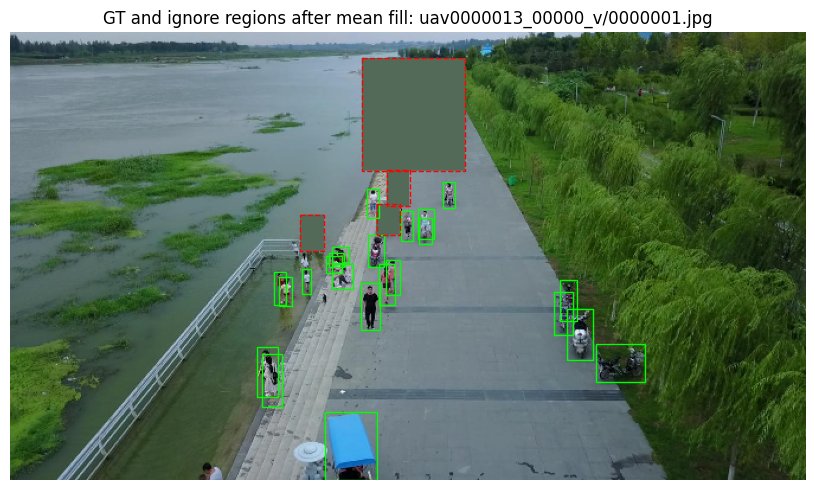

In [11]:
check_key = next(key for key, boxes in train_ignore_boxes_by_key.items() if len(boxes) > 0)
check_path = all_train_frames.filter(pl.col("frame_key") == check_key)["path"].item()
check_image = fill_ignore_regions(
    decode_image(check_path, mode=ImageReadMode.RGB), train_ignore_boxes_by_key[check_key]
)
display_image, stride = downscale_for_display(check_image)
box_columns = ["x1", "y1", "x2", "y2"]
gt_boxes = pl.DataFrame(train_targets_by_key[check_key][:, :4], schema=box_columns, orient="row")
ignore_boxes = pl.DataFrame(train_ignore_boxes_by_key[check_key], schema=box_columns, orient="row")
drawn_boxes = pl.concat([gt_boxes.with_columns(kind=pl.lit("gt")), ignore_boxes.with_columns(kind=pl.lit("ignore"))])
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
ax.imshow(display_image)
for x1, y1, x2, y2, kind in drawn_boxes.iter_rows():
    is_gt = kind == "gt"
    ax.add_patch(
        Rectangle(
            (x1 / stride, y1 / stride),
            (x2 - x1) / stride,
            (y2 - y1) / stride,
            fill=False,
            edgecolor="lime" if is_gt else "red",
            linestyle="-" if is_gt else "--",
            linewidth=1,
        )
    )
ax.set_title(f"GT and ignore regions after mean fill: {check_key}")
ax.set_xlabel("x (downscaled px)")
ax.set_ylabel("y (downscaled px)")
ax.axis("off")
save_figure(fig, "gt_check", drawn_boxes)

Augmentation check: the same training frame (the one of the GT check, after the mean fill) unchanged, degraded at the strongest setting (width `DEGRADE_WIDTH_RANGE[0]`, JPEG quality `DEGRADE_JPEG_QUALITY_RANGE[0]`), and at the two ends of `BRIGHTNESS_RANGE`. The settings are fixed here, so the check does not draw from the training random state. The title of each panel gives its mean pixel value (0–255); the CSV holds the settings and the same numbers.

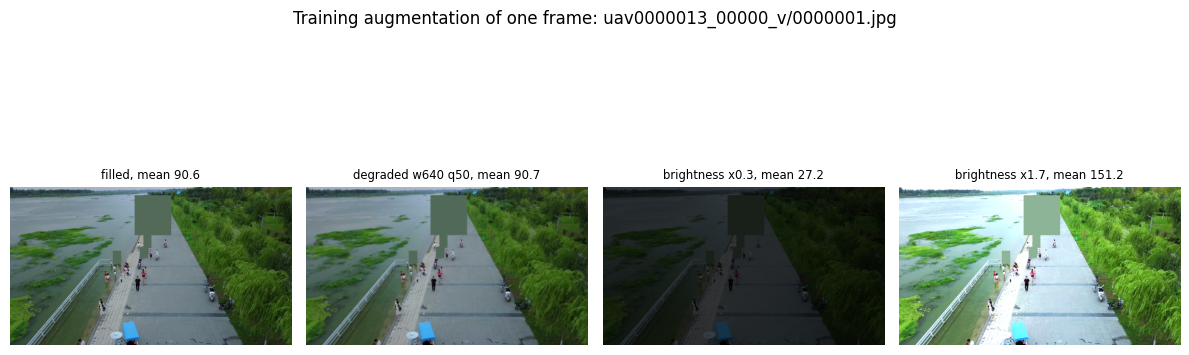

In [12]:
augmentation_examples = [
    ("filled", check_image),
    (
        f"degraded w{DEGRADE_WIDTH_RANGE[0]} q{DEGRADE_JPEG_QUALITY_RANGE[0]}",
        degrade_resolution(check_image, DEGRADE_WIDTH_RANGE[0], DEGRADE_JPEG_QUALITY_RANGE[0]),
    ),
    (f"brightness x{BRIGHTNESS_RANGE[0]}", scale_brightness(check_image, BRIGHTNESS_RANGE[0])),
    (f"brightness x{BRIGHTNESS_RANGE[1]}", scale_brightness(check_image, BRIGHTNESS_RANGE[1])),
]
fig, axes = plt.subplots(1, len(augmentation_examples), figsize=FIGURE_SIZE)
augmentation_rows = []
for ax, (transform_name, example) in zip(axes, augmentation_examples, strict=True):
    pixels, _ = downscale_for_display(example)
    mean_value = round(float(example.float().mean()), 1)
    ax.imshow(pixels)
    ax.set_title(f"{transform_name}, mean {mean_value}", fontsize="small")
    ax.set_xlabel("x (downscaled px)")
    ax.set_ylabel("y (downscaled px)")
    ax.axis("off")
    augmentation_rows.append({"transform": transform_name, "frame_key": check_key, "mean_value": mean_value})
fig.suptitle(f"Training augmentation of one frame: {check_key}")
save_figure(fig, "augmentation_check", pl.DataFrame(augmentation_rows))

## Model

The GIoU box loss lives in a subclass of torchvision's `RoIHeads`. The module-level `fastrcnn_loss` that `RoIHeads.forward` calls receives only the logits, the offsets and the encoded targets, not the proposals, so it cannot decode boxes; patching it would also change a torchvision module globally. `GiouRoIHeads.forward` therefore delegates to the parent in eval mode, so prediction and NMS are the torchvision ones, and runs its own training branch: it samples RoIs with the parent's `select_training_samples`, runs the box head and predictor, and builds the two losses under the same dictionary keys (`loss_classifier`, `loss_box_reg`) as torchvision, so logs, `history.csv` and the curves stay comparable with T1.

In the training branch the positive RoIs are the sampled RoIs with a foreground label. For each of them, the offsets of the ground-truth class are decoded against the proposal, and so are the encoded regression targets, which returns the matched GT box. The sum of `GIOU_LOSS_WEIGHT` × GIoU loss over the positives is divided by the number of sampled RoIs, as in torchvision. The decoding and the loss run with autocast disabled, on fp32 tensors.

In [13]:
class GiouRoIHeads(RoIHeads):
    def forward(
        self,
        features: dict[str, torch.Tensor],
        proposals: list[torch.Tensor],
        image_shapes: list[tuple[int, int]],
        targets: list[dict[str, torch.Tensor]] | None = None,
    ) -> tuple[list[dict[str, torch.Tensor]], dict[str, torch.Tensor]]:
        if not self.training:
            return super().forward(features, proposals, image_shapes, targets)
        if targets is None:
            raise ValueError("Targets are required to compute the RoI head losses")
        sampled_proposals, _, labels, regression_targets = self.select_training_samples(proposals, targets)
        box_features = self.box_head(self.box_roi_pool(features, sampled_proposals, image_shapes))
        class_logits, box_regression = self.box_predictor(box_features)
        all_labels = torch.cat(labels)
        positive_indices = torch.where(all_labels > 0)[0]
        positive_labels = all_labels[positive_indices]
        positive_proposals = torch.cat(sampled_proposals)[positive_indices]
        positive_offsets = box_regression.reshape(all_labels.numel(), -1, 4)[positive_indices, positive_labels]
        positive_targets = torch.cat(regression_targets)[positive_indices]
        with torch.autocast("cuda", enabled=False):
            predicted_boxes = self.box_coder.decode_single(positive_offsets.float(), positive_proposals.float())
            target_boxes = self.box_coder.decode_single(positive_targets.float(), positive_proposals.float())
            box_loss = generalized_box_iou_loss(predicted_boxes, target_boxes, reduction="sum")
        losses = {
            "loss_classifier": cross_entropy(class_logits, all_labels),
            "loss_box_reg": GIOU_LOSS_WEIGHT * box_loss / all_labels.numel(),
        }
        return [], losses

Model construction: `fasterrcnn_resnet50_fpn_v2` with COCO weights; only the box predictor is replaced with one for 8 classes plus background. The RPN anchor generator is replaced with `AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)`; the number of anchors per location is compared with the default generator, so the pretrained RPN head is guaranteed to fit. The RoI heads are rebuilt as `GiouRoIHeads` from the parts of the torchvision heads (pooler, box head, new predictor, matcher thresholds, sampler settings, box coder weights, score threshold, NMS threshold and detection limit), so nothing but the loss differs. `min_size = max_size = IMAGE_SIZE`, score threshold `CONF_THRESHOLD`, `MAX_DETECTIONS` per image, `box_nms_thresh` is `BOX_NMS_THRESHOLD`. The type checks make the replacements fail loudly if torchvision changes the heads.

In [14]:
def build_model() -> FasterRCNN:
    model = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1,
        min_size=IMAGE_SIZE,
        max_size=IMAGE_SIZE,
        box_score_thresh=CONF_THRESHOLD,
        box_detections_per_img=MAX_DETECTIONS,
        box_nms_thresh=BOX_NMS_THRESHOLD,
    )
    box_predictor = model.roi_heads.box_predictor
    if not isinstance(box_predictor, FastRCNNPredictor):
        raise RuntimeError(f"Unexpected box predictor: {type(box_predictor).__name__}")
    roi_heads = model.roi_heads
    if not isinstance(roi_heads, RoIHeads):
        raise RuntimeError(f"Unexpected RoI heads: {type(roi_heads).__name__}")
    model.roi_heads = GiouRoIHeads(
        roi_heads.box_roi_pool,
        roi_heads.box_head,
        FastRCNNPredictor(box_predictor.cls_score.in_features, len(CLASSES) + 1),
        fg_iou_thresh=roi_heads.proposal_matcher.high_threshold,
        bg_iou_thresh=roi_heads.proposal_matcher.low_threshold,
        batch_size_per_image=roi_heads.fg_bg_sampler.batch_size_per_image,
        positive_fraction=roi_heads.fg_bg_sampler.positive_fraction,
        bbox_reg_weights=roi_heads.box_coder.weights,
        score_thresh=roi_heads.score_thresh,
        nms_thresh=roi_heads.nms_thresh,
        detections_per_img=roi_heads.detections_per_img,
    )
    rpn = model.rpn
    if not isinstance(rpn, RegionProposalNetwork):
        raise RuntimeError(f"Unexpected RPN: {type(rpn).__name__}")
    anchor_generator = AnchorGenerator(ANCHOR_SIZES, ANCHOR_ASPECT_RATIOS)
    if anchor_generator.num_anchors_per_location() != rpn.anchor_generator.num_anchors_per_location():
        raise RuntimeError("The new anchors change the anchors per location: the pretrained RPN head would not fit")
    rpn.anchor_generator = anchor_generator
    return model.to(DEVICE)


model = build_model()
parameter_count = sum(parameter.numel() for parameter in model.parameters())
anchor_sizes = [level_sizes[0] for level_sizes in ANCHOR_SIZES]
print(
    f"fasterrcnn_resnet50_fpn_v2 | {parameter_count / 1e6:.1f} M parameters | {len(CLASSES) + 1} output classes "
    f"| anchor sizes per level {anchor_sizes} | RoI box loss GIoU x {GIOU_LOSS_WEIGHT}"
)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 238MB/s]


fasterrcnn_resnet50_fpn_v2 | 43.3 M parameters | 9 output classes | anchor sizes per level [16, 32, 64, 128, 256] | RoI box loss GIoU x 10.0


## Training

Optimiser and schedule follow the torchvision detection reference scripts: SGD with momentum 0.9 and weight decay 1e-4, a 500-iteration linear warmup, then cosine decay to 1 % of the base LR. Training uses AMP with gradient clipping at norm 10; batches with a non-finite loss are skipped and counted. BatchNorm statistics in the backbone and FPN stay frozen, because batch-4 statistics are too noisy. The schedule is 6 epochs (`EPOCHS`), as in T11. Each epoch builds its own loader with `build_train_loader(epoch - 1)`, which selects the frame offset `(epoch - 1) % FRAME_STEP` (the rotation of P2); the cosine decay is built over `sum(steps_by_epoch)` iterations, because the offsets have slightly different numbers of frames.

Each training frame is mean-filled, degraded with probability `DEGRADE_PROBABILITY` and flipped in the loader workers; on the GPU, `apply_colour_jitter` then scales its brightness, saturation and hue (Data section). In this run `loss_box_reg` is the GIoU term of the RoI head (see Model); the other three components are the torchvision ones.

After every epoch, our COCOeval runs on the quick-val frames, and `best.pt` is overwritten when quick-val mAP@500 improves. After epoch 1 the planned epochs shrink to fit `MAX_TRAIN_HOURS`, and the loop stops when the next epoch would end after the budget. After the loop, the weights of the last epoch are saved to `FINAL_EPOCH_WEIGHTS` in `SCRATCH_DIR`; they are evaluated in the Validation section and are not an output file.

First, the COCO helpers: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing.

In [15]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [16]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Prediction in fp32 without autocast: fp16 box decoding costs about 1 px, which matters for 10–30 px objects. Boxes are clipped to the image, label 0 (background) is dropped, and labels are converted back to 0-based class ids. Timing follows `SPEED_PROTOCOL`.

In [17]:
def predict_torchvision(model: torch.nn.Module, frame_paths: list[str]) -> tuple[dict[str, FrameDetections], float]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    model.eval()
    detections_by_key = {}
    inference_seconds = 0.0
    timed_images = 0
    with torch.no_grad():
        for batch_index, (images, batch_paths) in enumerate(loader):
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
            torch.cuda.synchronize()
            tick = time.perf_counter()
            outputs = model(images_on_device)
            torch.cuda.synchronize()
            if batch_index > 0:
                inference_seconds += time.perf_counter() - tick
                timed_images += len(images)
            for path, image, output in zip(batch_paths, images, outputs, strict=True):
                height, width = image.shape[-2:]
                is_object = output["labels"] > 0
                boxes = output["boxes"][is_object].float().cpu().numpy()
                boxes = boxes.clip(0, np.array([width, height, width, height], dtype=np.float32))
                scores = output["scores"][is_object].float().cpu().numpy()
                class_ids = (output["labels"][is_object] - 1).cpu().numpy()
                detections_by_key[to_frame_key(path)] = (boxes, scores, class_ids)
    return detections_by_key, 1000 * inference_seconds / timed_images

Optimiser, warmup plus cosine schedule, and BatchNorm freezing. `lr_schedule` holds the total iteration count, so the cosine can be rebuilt when the time guard shortens the run.

In [18]:
def freeze_batch_norm_statistics(module: torch.nn.Module) -> None:
    for layer in module.modules():
        if isinstance(layer, torch.nn.BatchNorm2d):
            layer.eval()


parameters = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.SGD(parameters, lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
lr_schedule = {"total_iterations": sum(steps_by_epoch)}


def compute_lr_factor(step: int) -> float:
    if step < WARMUP_ITERATIONS:
        return WARMUP_START_FACTOR + (1 - WARMUP_START_FACTOR) * step / WARMUP_ITERATIONS
    decay_iterations = max(lr_schedule["total_iterations"] - WARMUP_ITERATIONS, 1)
    progress = min((step - WARMUP_ITERATIONS) / decay_iterations, 1.0)
    return FINAL_LR_FACTOR + (1 - FINAL_LR_FACTOR) * 0.5 * (1 + math.cos(math.pi * progress))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, compute_lr_factor)

The training loop (P2's loop with the colour jitter applied to every training frame on the GPU): one log line per epoch, quick-val COCOeval, best checkpoint, time guard. `history.csv` is rewritten after every epoch, so a crashed session still leaves the log. Its extra columns `frame_offset` and `steps` record the frame offset and the optimiser steps of the epoch.

In [19]:
scaler = torch.amp.GradScaler("cuda")
history_rows: list[dict[str, float]] = []
skipped_batches = 0
planned_epochs = EPOCHS
training_started = time.time()
epoch = 0
while epoch < planned_epochs:
    epoch += 1
    epoch_started = time.time()
    train_loader = build_train_loader(epoch - 1)
    model.train()
    freeze_batch_norm_statistics(model.backbone)
    loss_sums: dict[str, float] = {}
    steps = 0
    for images, targets in train_loader:
        images_on_device = [apply_colour_jitter(image.to(DEVICE, non_blocking=True)).float() / 255 for image in images]
        targets_on_device = [
            {name: value.to(DEVICE, non_blocking=True) for name, value in target.items()} for target in targets
        ]
        with torch.autocast("cuda", dtype=torch.float16):
            loss_by_name = model(images_on_device, targets_on_device)
            loss = torch.stack(list(loss_by_name.values())).sum()
        if not torch.isfinite(loss):
            skipped_batches += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
            continue
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(parameters, GRADIENT_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad(set_to_none=True)
        scheduler.step()
        for name, value in loss_by_name.items():
            loss_sums[name] = loss_sums.get(name, 0.0) + value.item()
        steps += 1

    quick_val_detections, _ = predict_torchvision(model, quick_val_frames["path"].to_list())
    quick_val_evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(quick_val_detections, val_image_id_by_key), quick_val_image_ids
    )
    row = {
        "epoch": epoch,
        **{f"train/{name}": round(total / steps, 4) for name, total in loss_sums.items()},
        "val_mAP": round(compute_map_at_max_detections(quick_val_evaluator), 4),
        "val_AP50": round(float(quick_val_evaluator.stats[1]), 4),
        "lr": optimizer.param_groups[0]["lr"],
        "frame_offset": (epoch - 1) % FRAME_STEP,
        "steps": len(train_loader),
        "minutes": round((time.time() - epoch_started) / 60, 1),
    }
    is_best = all(row["val_mAP"] > previous["val_mAP"] for previous in history_rows)
    history_rows.append(row)
    if is_best:
        torch.save(model.state_dict(), OUTPUT_DIR / "best.pt")
    pl.DataFrame(history_rows).write_csv(OUTPUT_DIR / "history.csv")

    elapsed_hours = (time.time() - training_started) / 3600
    if epoch == 1 and int(MAX_TRAIN_HOURS / elapsed_hours) < planned_epochs:
        planned_epochs = max(int(MAX_TRAIN_HOURS / elapsed_hours), 2)
        lr_schedule["total_iterations"] = sum(steps_by_epoch[:planned_epochs])
    print(
        f"epoch {epoch}/{planned_epochs} | {row['minutes']} min "
        f"| offset {row['frame_offset']} | loss {sum(loss_sums.values()) / steps:.3f} "
        f"| quick-val mAP {row['val_mAP']:.4f} | AP50 {row['val_AP50']:.4f}{' | best' if is_best else ''}",
        flush=True,
    )
    if epoch < planned_epochs and elapsed_hours + elapsed_hours / epoch > MAX_TRAIN_HOURS:
        break

train_hours = (time.time() - training_started) / 3600
torch.save(model.state_dict(), FINAL_EPOCH_WEIGHTS)
best_epoch = int(max(history_rows, key=lambda history_row: history_row["val_mAP"])["epoch"])
print(f"training {train_hours:.2f} h | epochs {len(history_rows)} | best {best_epoch} | skipped {skipped_batches}")

/tmp/ipykernel_23/775921323.py:34: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


epoch 1/6 | 17.5 min | offset 0 | loss 1.152 | quick-val mAP 0.2245 | AP50 0.4762 | best
epoch 2/6 | 17.6 min | offset 1 | loss 0.917 | quick-val mAP 0.2229 | AP50 0.4685
epoch 3/6 | 17.5 min | offset 2 | loss 0.845 | quick-val mAP 0.2444 | AP50 0.4988 | best
epoch 4/6 | 17.4 min | offset 3 | loss 0.797 | quick-val mAP 0.2480 | AP50 0.5015 | best
epoch 5/6 | 17.3 min | offset 4 | loss 0.762 | quick-val mAP 0.2467 | AP50 0.4942
epoch 6/6 | 17.4 min | offset 0 | loss 0.743 | quick-val mAP 0.2491 | AP50 0.4961 | best
training 1.75 h | epochs 6 | best 6 | skipped 0


Training curves: loss components per epoch (RPN: `loss_objectness`, `loss_rpn_box_reg`; RoI head: `loss_classifier`, and `loss_box_reg`, which is the GIoU term in this run) and quick-val metrics.

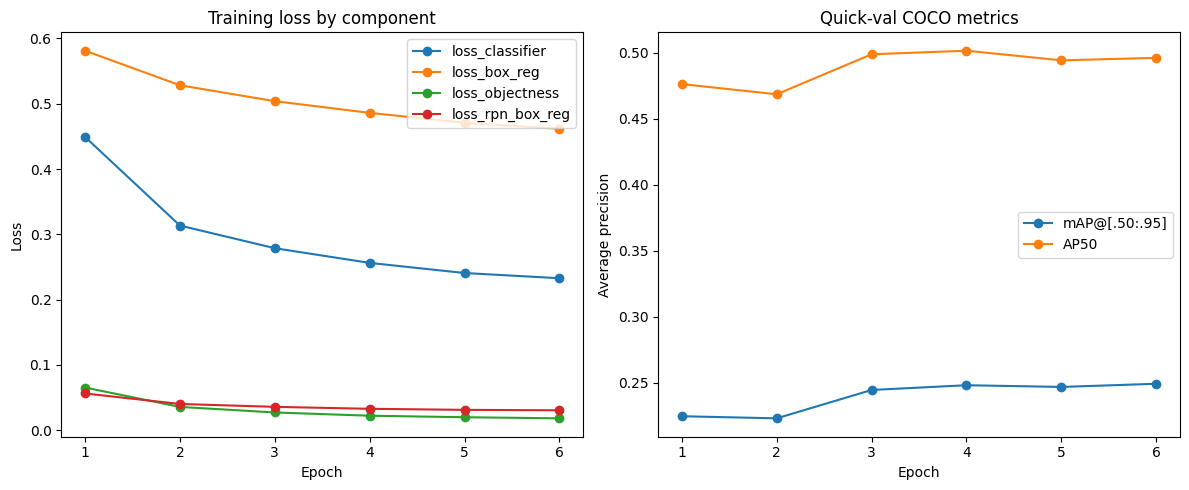

In [20]:
history = pl.DataFrame(history_rows)
loss_columns = [name for name in history.columns if name.startswith("train/")]
fig, (loss_ax, metric_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for column in loss_columns:
    loss_ax.plot(history["epoch"], history[column], marker="o", label=column.removeprefix("train/"))
loss_ax.set_title("Training loss by component")
loss_ax.set_xlabel("Epoch")
loss_ax.set_ylabel("Loss")
loss_ax.legend()
metric_ax.plot(history["epoch"], history["val_mAP"], marker="o", label="mAP@[.50:.95]")
metric_ax.plot(history["epoch"], history["val_AP50"], marker="o", label="AP50")
metric_ax.set_title("Quick-val COCO metrics")
metric_ax.set_xlabel("Epoch")
metric_ax.set_ylabel("Average precision")
metric_ax.legend()
save_figure(fig, "training_curves", history)

## Validation

The best checkpoint by quick-val mAP@500 is evaluated on all val frames. Quick val is a subset of val, so this score is slightly optimistic. Speed protocol: `perf_counter` around `model(images)` including the internal resize and NMS, with `cuda.synchronize`, batch `BATCH_SIZE`, fp32, Tesla T4, all val frames, first batch excluded. The final-epoch weights are evaluated on the same frames right after, so that the best-quick-val checkpoint and the last-epoch checkpoint are reported side by side.

In [21]:
model.load_state_dict(torch.load(OUTPUT_DIR / "best.pt", map_location=DEVICE, weights_only=True))
val_detections_by_key, ms_per_image = predict_torchvision(model, val_frames["path"].to_list())
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} | {ms_per_image:.1f} ms/image")

950017 detections | mAP 0.2462 | 239.9 ms/image


Final-epoch weights on all val frames. The question: how does the checkpoint at the end of the 6-epoch schedule compare with the best-quick-val checkpoint? A second model is built, the weights saved after the last epoch are loaded, and the same prediction and COCOeval path as above is applied. These detections are not written to `val_predictions.json` (that file holds the best-checkpoint detections, as in every run), and the analysis sections below keep using the best checkpoint in `model`.

In [22]:
final_epoch_model = build_model()
final_epoch_model.load_state_dict(torch.load(FINAL_EPOCH_WEIGHTS, map_location=DEVICE, weights_only=True))
final_epoch_detections_by_key, _ = predict_torchvision(final_epoch_model, val_frames["path"].to_list())
final_epoch_evaluator = evaluate_coco(
    val_ground_truth, to_coco_results(final_epoch_detections_by_key, val_image_id_by_key)
)
final_epoch_metrics = summarise_metrics(final_epoch_evaluator)
del final_epoch_model
torch.cuda.empty_cache()
print(
    f"final epoch {len(history_rows)} | mAP {final_epoch_metrics['mAP']:.4f} "
    f"| AP_small {final_epoch_metrics['AP_small']:.4f}"
)

final epoch 6 | mAP 0.2462 | AP_small 0.1261


Best-quick-val checkpoint and final-epoch checkpoint, both on all val frames. How to read this table: one row per checkpoint, `epoch` is the 1-based epoch of the weights, the metric columns are the `result.json` metrics. When the best epoch is the last one, the two rows come from the same weights. Written to `checkpoint_comparison.csv`.

In [23]:
checkpoint_comparison = pl.DataFrame(
    [
        {"checkpoint": "best quick-val", "epoch": best_epoch, **val_metrics},
        {"checkpoint": "final epoch", "epoch": len(history_rows), **final_epoch_metrics},
    ]
)
checkpoint_comparison.write_csv(OUTPUT_DIR / "checkpoint_comparison.csv")
checkpoint_comparison

checkpoint,epoch,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""best quick-val""",6,0.2462,0.246,0.4934,0.2181,0.1261,0.2228,0.4336,0.4723
"""final epoch""",6,0.2462,0.246,0.4934,0.2181,0.1261,0.2228,0.4336,0.4723


`result.json` writer: the core keys are checked before writing.

In [24]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without `versions` and `changed_params`).

In [25]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": IMAGE_SIZE,
    "epochs_planned": EPOCHS,
    "epochs_run": len(history_rows),
    "best_epoch": best_epoch,
    "batch": BATCH_SIZE,
    "lr": LEARNING_RATE,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(train_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "anchor_sizes": [level_sizes[0] for level_sizes in ANCHOR_SIZES],
    "box_loss": "giou",
    "giou_loss_weight": GIOU_LOSS_WEIGHT,
    "box_nms_threshold": BOX_NMS_THRESHOLD,
    "augmentation": {
        "brightness_range": list(BRIGHTNESS_RANGE),
        "saturation_range": list(SATURATION_RANGE),
        "hue_shift": HUE_SHIFT,
        "degrade_probability": DEGRADE_PROBABILITY,
        "degrade_width_range": list(DEGRADE_WIDTH_RANGE),
        "degrade_jpeg_quality_range": list(DEGRADE_JPEG_QUALITY_RANGE),
        "horizontal_flip_probability": HORIZONTAL_FLIP_PROBABILITY,
    },
    "source_kernels": list(SOURCE_KERNELS),
    "mAP_final_epoch": final_epoch_metrics["mAP"],
    "AP_small_final_epoch": final_epoch_metrics["AP_small"],
    "final_epoch": len(history_rows),
    "frame_offset_rotation": FRAME_OFFSET_ROTATION,
    "frame_offsets": [row["frame_offset"] for row in history_rows],
    "train_frames_seen": all_train_frames.filter(
        pl.col("frame_offset").is_in([row["frame_offset"] for row in history_rows])
    ).height,
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if key not in ("versions", "changed_params")}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,anchor_sizes,box_loss,giou_loss_weight,box_nms_threshold,augmentation,source_kernels,mAP_final_epoch,AP_small_final_epoch,final_epoch,frame_offset_rotation,frame_offsets,train_frames_seen
str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,f64,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,list[i64],str,f64,f64,struct[7],list[str],f64,f64,i64,str,list[i64],i64
"""faster-rcnn-combined""","""new-notebooks/faster-rcnn-comb…","""torchvision fasterrcnn_resnet5…","""pipeline""","""tuned""","""faster-rcnn-giou""",42,1280,6,6,6,4,0.005,4868,2846,5,"""per_image_mean_fill""",0.2462,0.246,0.4934,0.2181,0.1261,0.2228,0.4336,0.4723,239.9,"""perf_counter around model(imag…",1.75,"""Tesla T4""","""2026-11-07T19:24:45+00:00""","""2026-11-07T21:43:45+00:00""","[16, 32, … 256]","""giou""",10.0,0.5,"{[0.3, 1.7],[0.3, 1.7],0.015,0.3,[640, 1000],[50, 90],0.5}","[""dmnk1304/faster-rcnn-giou""]",0.2462,0.1261,6,"""epoch_index_mod_frame_step""","[0, 1, … 0]",24201


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [26]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.2851,0.687
1,"""bicycle""",0.2396,0.563
2,"""car""",0.3972,0.6632
3,"""van""",0.2608,0.4611
4,"""truck""",0.3151,0.5408
5,"""tricycle""",0.251,0.5395
6,"""bus""",0.0952,0.1196
7,"""motor""",0.1254,0.3731


Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the full-val detections are filtered to the clip's frames and evaluated against the same ground truth. How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [27]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.1765,0.4824,0.2404
"""uav0000117_02622_v""",349,0.2669,0.5296,0.0237
"""uav0000137_00458_v""",233,0.3243,0.6982,0.03
"""uav0000182_00000_v""",363,0.2085,0.4714,0.1455
"""uav0000268_05773_v""",978,0.1282,0.2297,0.0011
"""uav0000305_00000_v""",184,0.3108,0.4505,0.0422
"""uav0000339_00001_v""",275,0.2845,0.522,0.0829


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [28]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.2462,0.4934,0.4723,0.8225
"""small""",21910,0.1261,0.3497,0.2982,0.718
"""medium""",79357,0.2228,0.4787,0.4406,0.8083
"""large""",12865,0.4336,0.7135,0.654,0.9663


RPN recall against final recall. The question: how many GT boxes does the first stage already cover, and how many are still covered after the second stage? The RPN is run on the quick-val frames with the best checkpoint in eval mode (`model.transform`, `model.backbone`, `model.rpn`); its post-NMS proposals (the torchvision default of 1000 at test time, as in T1) are mapped back to original pixels. The code adapts section 5 of the legacy `faster-cnn-5`, as T1 does. For every GT box the best IoU over all proposals and over all final detections of any class (up to 500 per frame, score ≥ 0.001, taken from the full-val predictions of the same frames) is computed.

In [29]:
def predict_rpn_proposals(model: FasterRCNN, frame_paths: list[str]) -> dict[str, np.ndarray]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    model.eval()
    proposals_by_key = {}
    with torch.no_grad():
        for images, batch_paths in loader:
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in images]
            image_list, _ = model.transform(images_on_device)
            proposals, _ = model.rpn(image_list, model.backbone(image_list.tensors))
            for path, image, proposal, resized_size in zip(
                batch_paths, images, proposals, image_list.image_sizes, strict=True
            ):
                height, width = image.shape[-2:]
                scale = np.array(
                    [width / resized_size[1], height / resized_size[0]] * 2,
                    dtype=np.float32,
                )
                proposals_by_key[to_frame_key(path)] = proposal.float().cpu().numpy() * scale
    return proposals_by_key


quick_val_keys = quick_val_frames["frame_key"].to_list()
proposals_by_key = predict_rpn_proposals(model, quick_val_frames["path"].to_list())
print(f"RPN proposals per frame: {np.mean([len(proposals) for proposals in proposals_by_key.values()]):.1f}")

RPN proposals per frame: 1000.0


How to read this table: one row per size group. `bin_kind` is `coco` for the COCO size buckets in original pixels (`all` is the total) and `side` for bins of the box side `sqrt(w*h)` in original pixels (edges `SIDE_BIN_EDGES`); the two kinds cover the same GT boxes, so rows of different kinds overlap. `rpn_recall_50` and `rpn_recall_70` are the shares of GT boxes with at least one RPN proposal at IoU ≥ 0.5 and ≥ 0.7; `final_recall_50` and `final_recall_70` are the same shares for the final detections of any class. Written to `rpn_recall.csv`.

In [30]:
def compute_best_ious(gt_boxes: np.ndarray, candidate_boxes: np.ndarray) -> np.ndarray:
    if len(gt_boxes) == 0 or len(candidate_boxes) == 0:
        return np.zeros(len(gt_boxes), dtype=np.float32)
    return torch.amax(box_iou(torch.from_numpy(gt_boxes), torch.from_numpy(candidate_boxes)), dim=1).numpy()


def collect_gt_areas(keys: list[str]) -> np.ndarray:
    return np.concatenate(
        [
            (val_targets_by_key[key][:, 2] - val_targets_by_key[key][:, 0])
            * (val_targets_by_key[key][:, 3] - val_targets_by_key[key][:, 1])
            for key in keys
        ]
    )


def collect_best_ious(keys: list[str], boxes_by_key: dict[str, np.ndarray]) -> np.ndarray:
    return np.concatenate([compute_best_ious(val_targets_by_key[key][:, :4], boxes_by_key[key]) for key in keys])


def summarise_recall(best_ious: pl.DataFrame, iou_columns: list[str]) -> pl.DataFrame:
    labelled = best_ious.with_columns(
        size=pl.when(pl.col("area") < SMALL_AREA)
        .then(pl.lit("small"))
        .when(pl.col("area") < MEDIUM_AREA)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("large")),
    ).with_columns(
        side_bin=pl.Series(
            "side_bin",
            np.array(SIDE_BIN_LABELS)[
                np.searchsorted(SIDE_BIN_EDGES, np.sqrt(best_ious["area"].to_numpy()), side="right")
            ].tolist(),
        )
    )
    recall_columns = [
        (pl.col(column) >= threshold)
        .mean()
        .round(4)
        .alias(f"{column.removesuffix('_iou')}_recall_{round(100 * threshold)}")
        for column in iou_columns
        for threshold in (0.5, 0.7)
    ]
    groupings = [
        (
            "coco",
            pl.concat(
                [
                    labelled.select("size", *iou_columns),
                    labelled.select(pl.lit("all").alias("size"), *iou_columns),
                ]
            ),
        ),
        ("side", labelled.select(pl.col("side_bin").alias("size"), *iou_columns)),
    ]
    order_by_size = {name: index for index, name in enumerate(["all", "small", "medium", "large", *SIDE_BIN_LABELS])}
    return (
        pl.concat(
            [
                grouped.group_by("size")
                .agg(pl.len().alias("objects"), *recall_columns)
                .with_columns(bin_kind=pl.lit(kind))
                for kind, grouped in groupings
            ]
        )
        .sort(pl.col("size").replace_strict(order_by_size))
        .select("bin_kind", "size", "objects", *[expression.meta.output_name() for expression in recall_columns])
    )

In [31]:
gt_areas = collect_gt_areas(quick_val_keys)
rpn_recall = summarise_recall(
    pl.DataFrame(
        {
            "area": gt_areas,
            "rpn_iou": collect_best_ious(quick_val_keys, proposals_by_key),
            "final_iou": collect_best_ious(
                quick_val_keys, {key: val_detections_by_key[key][0] for key in quick_val_keys}
            ),
        }
    ),
    ["rpn_iou", "final_iou"],
)
rpn_recall.write_csv(OUTPUT_DIR / "rpn_recall.csv")
rpn_recall

bin_kind,size,objects,rpn_recall_50,rpn_recall_70,final_recall_50,final_recall_70
str,str,u32,f64,f64,f64,f64
"""coco""","""all""",22906,0.8789,0.6698,0.835,0.5671
"""coco""","""small""",4393,0.7806,0.5131,0.7114,0.3433
"""coco""","""medium""",15917,0.8879,0.6686,0.8441,0.57
"""coco""","""large""",2596,0.9904,0.9422,0.9884,0.928
"""side""","""<16 px""",77,0.2857,0.1299,0.2597,0.039
"""side""","""16-32 px""",4316,0.7894,0.5199,0.7194,0.3487
"""side""","""32-64 px""",10553,0.8563,0.6023,0.801,0.4842
"""side""","""64-128 px""",6768,0.9598,0.8252,0.9425,0.7707
"""side""","""128-256 px""",931,0.9764,0.9527,0.9764,0.9635


Missed GT by attribute. The question: which GT boxes does the final detector not find, split by the annotated `occlusion` (0 none, 1 partial, 2 heavy) and `truncation` (0 none, 1 partial) levels and by size bucket? A GT box counts as missed when no final detection of any class, among the up to 500 per frame, has IoU ≥ `MISSED_IOU_THRESHOLD` = 0.5 with it. The annotations come from `val/annotations_coco.json` with the same filter as the GT used for evaluation (`iscrowd=0`, box side at least 1 px), over all 2,846 val frames. Size buckets are COCO's, in original pixels (small < 32², medium < 96², large otherwise). The val ignore boxes (`iscrowd=1`) are read here as well, for the failure cases. How to read this table: one row per `occlusion` x `truncation` x `size` group; `objects` is the GT count, `missed` the number of missed boxes and `missed_share` their fraction of `objects`. Written to `missed_by_attribute.csv`.

In [32]:
def build_box_corner_columns() -> list[pl.Expr]:
    return [
        pl.col("bbox").list.get(0).alias("x1"),
        pl.col("bbox").list.get(1).alias("y1"),
        (pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2)).alias("x2"),
        (pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3)).alias("y2"),
    ]


def load_val_annotations() -> pl.DataFrame:
    coco = json.loads((DATA_ROOT / "val" / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        image_id=pl.col("id"), frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
    )
    return pl.DataFrame(coco["annotations"]).join(images, on="image_id")


def attach_best_final_iou(gt_annotations: pl.DataFrame) -> pl.DataFrame:
    parts = []
    for (key,), frame_gt in gt_annotations.group_by("frame_key", maintain_order=True):
        gt_boxes = frame_gt.select("x1", "y1", "x2", "y2").to_numpy().astype(np.float32)
        final_iou = compute_best_ious(gt_boxes, val_detections_by_key[str(key)][0])
        parts.append(frame_gt.with_columns(final_iou=pl.Series("final_iou", final_iou, dtype=pl.Float64)))
    return pl.concat(parts)


val_annotations = load_val_annotations()
val_ignore_boxes_by_key = {key: np.zeros((0, 4), dtype=np.float32) for key in val_images["frame_key"]}
for (key,), frame_regions in val_annotations.filter(pl.col("iscrowd") == 1).group_by("frame_key"):
    val_ignore_boxes_by_key[str(key)] = frame_regions.select(build_box_corner_columns()).to_numpy().astype(np.float32)
gt_annotations = (
    val_annotations.filter(pl.col("iscrowd") == 0)
    .select("frame_key", "occlusion", "truncation", *build_box_corner_columns(), class_id=pl.col("category_id") - 1)
    .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
    .with_columns(area=(pl.col("x2") - pl.col("x1")) * (pl.col("y2") - pl.col("y1")))
)
gt_outcomes = attach_best_final_iou(gt_annotations)
missed_by_attribute = (
    gt_outcomes.with_columns(
        size=pl.when(pl.col("area") < SMALL_AREA)
        .then(pl.lit("small"))
        .when(pl.col("area") < MEDIUM_AREA)
        .then(pl.lit("medium"))
        .otherwise(pl.lit("large")),
        is_missed=pl.col("final_iou") < MISSED_IOU_THRESHOLD,
    )
    .group_by("occlusion", "truncation", "size")
    .agg(objects=pl.len(), missed=pl.col("is_missed").sum())
    .with_columns(missed_share=(pl.col("missed") / pl.col("objects")).round(4))
    .sort("occlusion", "truncation", pl.col("size").replace_strict({"small": 0, "medium": 1, "large": 2}))
)
missed_by_attribute.write_csv(OUTPUT_DIR / "missed_by_attribute.csv")
missed_by_attribute

occlusion,truncation,size,objects,missed,missed_share
i64,i64,str,u32,u32,f64
0,0,"""small""",7004,1523,0.2174
0,0,"""medium""",29758,1593,0.0535
0,0,"""large""",6982,21,0.003
0,1,"""small""",369,98,0.2656
0,1,"""medium""",1141,33,0.0289
…,…,…,…,…,…
2,0,"""medium""",4769,3023,0.6339
2,0,"""large""",128,5,0.0391
2,1,"""small""",62,62,1.0


Three failure cases from the quick-val frames, taken from the full-val detections of the best checkpoint. Selection rules, all deterministic:
1. A missed small object: among the small GT boxes (< 32²) with a best IoU below `FAILURE_MISS_IOU` = 0.3 to any final detection, the one with the largest area.
2. A false positive outside ignore regions: among the detections with score ≥ `FAILURE_SCORE_THRESHOLD` = 0.5 whose IoU with every GT box is below `FAILURE_FALSE_POSITIVE_IOU` = 0.1 and that do not overlap any val ignore box, the one with the highest score.
3. A class confusion: among the detections with score ≥ 0.5 that have IoU ≥ `FAILURE_MATCH_IOU` = 0.5 with a GT box of another class and IoU below 0.5 with every GT box of their own class, the highest-scoring one, taking the pairs tricycle/motor and van/car first (`PREFERRED_CONFUSIONS`) and any pair if none occurs. The notebook raises if a rule finds no candidate.

How to read the table: one row per case with the frame key and the focus box (`x1 y1 x2 y2`, original pixels): the GT box for case 1, the detection for cases 2 and 3.

Helpers for the selection: an overlap test against ignore boxes, the per-detection candidate table (best IoU to any GT box, to GT boxes of the same class and to GT boxes of other classes) and the deterministic top-case pick.

In [33]:
def mask_boxes_overlapping_regions(boxes: np.ndarray, regions: np.ndarray) -> np.ndarray:
    if len(boxes) == 0 or len(regions) == 0:
        return np.zeros(len(boxes), dtype=bool)
    is_overlapping = (
        (boxes[:, None, 0] < regions[None, :, 2])
        & (boxes[:, None, 2] > regions[None, :, 0])
        & (boxes[:, None, 1] < regions[None, :, 3])
        & (boxes[:, None, 3] > regions[None, :, 1])
    )
    return is_overlapping.any(axis=1)


def list_detection_candidates(keys: list[str]) -> pl.DataFrame:
    parts = []
    for key in keys:
        gt_targets = val_targets_by_key[key]
        boxes, scores, class_ids = val_detections_by_key[key]
        is_shown = scores >= FAILURE_SCORE_THRESHOLD
        boxes, scores, class_ids = boxes[is_shown], scores[is_shown], class_ids[is_shown]
        if len(boxes) == 0:
            continue
        ious = (
            box_iou(torch.from_numpy(boxes), torch.from_numpy(gt_targets[:, :4])).numpy()
            if len(gt_targets) > 0
            else np.zeros((len(boxes), 0), dtype=np.float32)
        )
        is_same_class = class_ids[:, None] == gt_targets[None, :, 4]
        other_ious = np.where(is_same_class, 0.0, ious)
        other_class_ids = gt_targets[other_ious.argmax(axis=1), 4] if len(gt_targets) > 0 else np.full(len(boxes), -1.0)
        parts.append(
            pl.DataFrame(
                {
                    "frame_key": [key] * len(boxes),
                    "x1": boxes[:, 0],
                    "y1": boxes[:, 1],
                    "x2": boxes[:, 2],
                    "y2": boxes[:, 3],
                    "score": scores,
                    "class_id": class_ids,
                    "other_class_id": other_class_ids.astype(np.int64),
                    "best_iou": ious.max(axis=1, initial=0.0),
                    "best_same_iou": np.where(is_same_class, ious, 0.0).max(axis=1, initial=0.0),
                    "best_other_iou": other_ious.max(axis=1, initial=0.0),
                    "is_ignored": mask_boxes_overlapping_regions(boxes, val_ignore_boxes_by_key[key]),
                },
                schema_overrides={"class_id": pl.Int64},
            )
        )
    return pl.concat(parts)


def select_top_case(candidates: pl.DataFrame, name: str, by: list[str], descending: list[bool]) -> pl.DataFrame:
    if candidates.height == 0:
        raise ValueError(f"No candidate for the failure case: {name}")
    return candidates.sort(by, descending=descending).head(1)

Apply the three selection rules to the quick-val frames and list the selected cases.

In [34]:
detection_candidates = list_detection_candidates(quick_val_keys)
preferred_pair_codes = [
    CLASSES.index(first) * len(CLASSES) + CLASSES.index(second) for first, second in PREFERRED_CONFUSIONS
]
missed_small_case = select_top_case(
    gt_outcomes.filter(
        pl.col("frame_key").is_in(quick_val_keys)
        & (pl.col("area") < SMALL_AREA)
        & (pl.col("final_iou") < FAILURE_MISS_IOU)
    ),
    "missed small object",
    ["area", "frame_key"],
    [True, False],
)
false_positive_case = select_top_case(
    detection_candidates.filter((pl.col("best_iou") < FAILURE_FALSE_POSITIVE_IOU) & ~pl.col("is_ignored")),
    "false positive outside ignore regions",
    ["score", "frame_key"],
    [True, False],
)
confusion_case = select_top_case(
    detection_candidates.filter(
        (pl.col("best_other_iou") >= FAILURE_MATCH_IOU) & (pl.col("best_same_iou") < FAILURE_MATCH_IOU)
    ).with_columns(
        is_preferred=(pl.col("class_id") * len(CLASSES) + pl.col("other_class_id")).is_in(preferred_pair_codes)
    ),
    "class confusion",
    ["is_preferred", "score", "frame_key"],
    [True, True, False],
)
pl.concat(
    [
        case.select("frame_key", pl.col("x1", "y1", "x2", "y2").cast(pl.Float64)).with_columns(case=pl.lit(number))
        for number, case in enumerate([missed_small_case, false_positive_case, confusion_case], start=1)
    ]
).select("case", "frame_key", "x1", "y1", "x2", "y2")

case,frame_key,x1,y1,x2,y2
i32,str,f64,f64,f64,f64
1,"""uav0000268_05773_v/0000361.jpg""",1964.0,753.0,1995.0,786.0
2,"""uav0000305_00000_v/0000166.jpg""",1751.014648,86.151665,1866.750488,213.197739
3,"""uav0000268_05773_v/0000086.jpg""",2094.529297,976.871338,2185.480469,1077.224365


Drawing helper for the failure cases. Each figure has two panels: the whole frame (downscaled to at most `FIGURE_IMAGE_MAX_SIDE` px) with the crop window in yellow, and the crop at original resolution (`FAILURE_CROP_SIZE` = 320 px square, centred on the focus box and kept inside the frame). In the crop: green boxes are GT, red boxes are detections with score ≥ 0.5, cyan dashed boxes are val ignore regions, and the thick yellow box is the focus box of the case. `fig_failure_<n>.csv` lists every drawn box with its frame key and crop origin.

In [35]:
val_path_by_key = dict(val_frames.select("frame_key", "path").iter_rows())
colour_by_kind = {"gt": "lime", "detection": "red", "ignore": "cyan", "focus": "yellow"}
DRAWN_SCHEMA = {
    "kind": pl.String,
    "class_name": pl.String,
    "score": pl.Float64,
    "x1": pl.Float64,
    "y1": pl.Float64,
    "x2": pl.Float64,
    "y2": pl.Float64,
}


def build_drawn_row(kind: str, class_name: str | None, score: float | None, box: list[float]) -> dict[str, object]:
    return {
        "kind": kind,
        "class_name": class_name,
        "score": score,
        "x1": box[0],
        "y1": box[1],
        "x2": box[2],
        "y2": box[3],
    }


def build_drawn_boxes(key: str, focus_box: list[float]) -> pl.DataFrame:
    boxes, scores, class_ids = val_detections_by_key[key]
    is_shown = scores >= FAILURE_SCORE_THRESHOLD
    drawn_rows = [
        *[
            build_drawn_row("gt", CLASSES[int(class_id)], None, [x1, y1, x2, y2])
            for x1, y1, x2, y2, class_id in val_targets_by_key[key].tolist()
        ],
        *[
            build_drawn_row("detection", CLASSES[int(class_id)], score, box)
            for box, score, class_id in zip(
                boxes[is_shown].tolist(), scores[is_shown].tolist(), class_ids[is_shown].tolist(), strict=True
            )
        ],
        *[build_drawn_row("ignore", None, None, box) for box in val_ignore_boxes_by_key[key].tolist()],
        build_drawn_row("focus", None, None, focus_box),
    ]
    return pl.DataFrame(drawn_rows, schema=DRAWN_SCHEMA)


def read_case_box(case: pl.DataFrame) -> list[float]:
    return [float(value) for value in case.select("x1", "y1", "x2", "y2").row(0)]

The figure function: it computes the crop window, builds the drawn boxes, draws both panels and saves the figure with its data.

In [36]:
def draw_failure_case(case_number: int, title: str, key: str, focus_box: list[float]) -> None:
    image = decode_image(val_path_by_key[key], mode=ImageReadMode.RGB)
    height, width = image.shape[-2:]
    left = int(np.clip((focus_box[0] + focus_box[2]) / 2 - FAILURE_CROP_SIZE / 2, 0, max(width - FAILURE_CROP_SIZE, 0)))
    top = int(np.clip((focus_box[1] + focus_box[3]) / 2 - FAILURE_CROP_SIZE / 2, 0, max(height - FAILURE_CROP_SIZE, 0)))
    crop = image[:, top : top + FAILURE_CROP_SIZE, left : left + FAILURE_CROP_SIZE]
    drawn = build_drawn_boxes(key, focus_box)
    fig, (frame_ax, crop_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
    display_frame, stride = downscale_for_display(image)
    frame_ax.imshow(display_frame)
    frame_ax.add_patch(
        Rectangle(
            (left / stride, top / stride),
            FAILURE_CROP_SIZE / stride,
            FAILURE_CROP_SIZE / stride,
            fill=False,
            edgecolor=colour_by_kind["focus"],
            linewidth=1.5,
        )
    )
    frame_ax.set_title(f"Frame {key} with crop window")
    frame_ax.set_xlabel("x (downscaled px)")
    frame_ax.set_ylabel("y (downscaled px)")
    frame_ax.axis("off")
    crop_ax.imshow(crop.permute(1, 2, 0).numpy())
    labels_seen: set[str] = set()
    for kind, x1, y1, x2, y2 in drawn.select("kind", "x1", "y1", "x2", "y2").iter_rows():
        crop_ax.add_patch(
            Rectangle(
                (x1 - left, y1 - top),
                x2 - x1,
                y2 - y1,
                fill=False,
                edgecolor=colour_by_kind[kind],
                linestyle="--" if kind == "ignore" else "-",
                linewidth=2 if kind == "focus" else 1,
                label=None if kind in labels_seen else kind,
            )
        )
        labels_seen.add(kind)
    crop_ax.set_xlim(0, crop.shape[-1])
    crop_ax.set_ylim(crop.shape[-2], 0)
    crop_ax.set_title(title)
    crop_ax.set_xlabel("x (crop px)")
    crop_ax.set_ylabel("y (crop px)")
    crop_ax.legend(loc="upper right", fontsize="small")
    save_figure(
        fig,
        f"failure_{case_number}",
        drawn.with_columns(frame_key=pl.lit(key), crop_left=pl.lit(left), crop_top=pl.lit(top)),
    )

Failure case 1: a missed small object. The focus box is the GT box; no detection reaches IoU 0.3 with it.

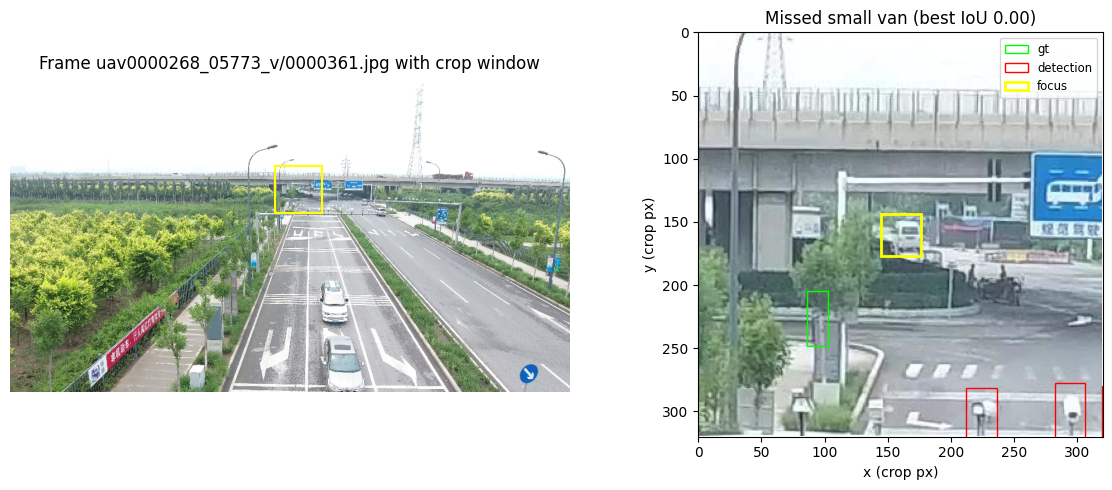

In [37]:
missed_small_class = CLASSES[int(missed_small_case["class_id"].item())]
draw_failure_case(
    1,
    f"Missed small {missed_small_class} (best IoU {missed_small_case['final_iou'].item():.2f})",
    str(missed_small_case["frame_key"].item()),
    read_case_box(missed_small_case),
)

Failure case 2: a false positive outside ignore regions. The focus box is the detection; it has IoU below 0.1 with every GT box and overlaps no ignore box.

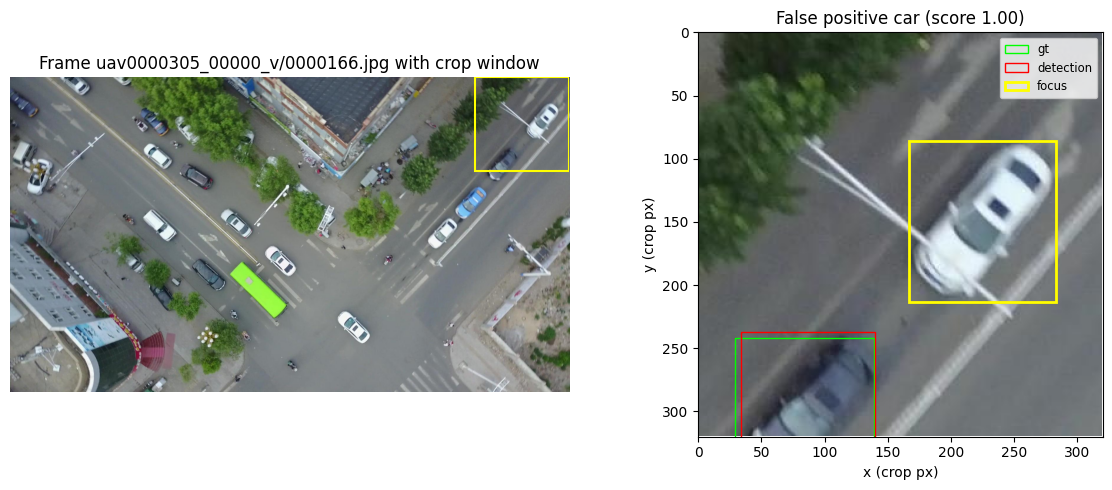

In [38]:
false_positive_class = CLASSES[int(false_positive_case["class_id"].item())]
draw_failure_case(
    2,
    f"False positive {false_positive_class} (score {false_positive_case['score'].item():.2f})",
    str(false_positive_case["frame_key"].item()),
    read_case_box(false_positive_case),
)

Failure case 3: a class confusion. The focus box is the detection; it matches a GT box of another class at IoU 0.5 or more.

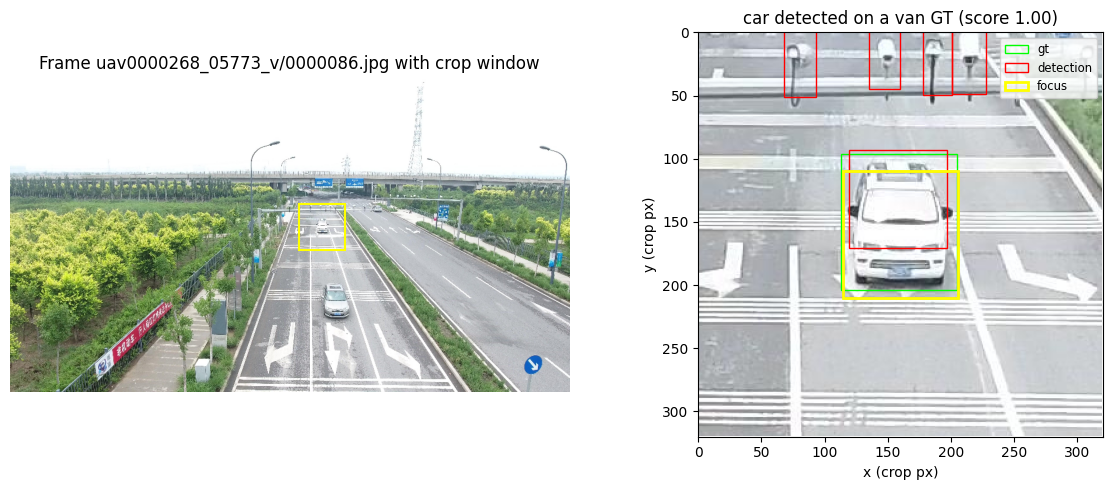

In [39]:
confusion_detected_class = CLASSES[int(confusion_case["class_id"].item())]
confusion_gt_class = CLASSES[int(confusion_case["other_class_id"].item())]
draw_failure_case(
    3,
    f"{confusion_detected_class} detected on a {confusion_gt_class} GT (score {confusion_case['score'].item():.2f})",
    str(confusion_case["frame_key"].item()),
    read_case_box(confusion_case),
)

NMS diagnostic (inference only, no retraining). The question: how does the final recall by size change when the second-stage NMS threshold `box_nms_thresh` is 0.5 (used for every number above and in the submission) or 0.6? The best checkpoint predicts the 571 quick-val frames at each threshold, and the threshold is reset to `BOX_NMS_THRESHOLD` afterwards. How to read this table: one row per `nms_threshold` x size group (`bin_kind`, `size` and `objects` as in `rpn_recall.csv`); `final_recall_50` and `final_recall_70` are the shares of GT boxes with a final detection of any class at IoU ≥ 0.5 and ≥ 0.7; `detections_per_frame` is the mean number of detections per quick-val frame; `ms_per_image` uses the speed protocol of the run on the quick-val frames only (it is not comparable with the full-val `ms_per_image` of `result.json`). Written to `nms_diagnostic.csv`.

In [40]:
def run_nms_diagnostic(thresholds: tuple[float, ...]) -> pl.DataFrame:
    roi_heads = model.roi_heads
    if not isinstance(roi_heads, RoIHeads):
        raise RuntimeError(f"Unexpected RoI heads: {type(roi_heads).__name__}")
    parts = []
    for threshold in thresholds:
        roi_heads.nms_thresh = threshold
        detections_by_key, milliseconds_per_image = predict_torchvision(model, quick_val_frames["path"].to_list())
        best_ious = pl.DataFrame(
            {
                "area": gt_areas,
                "final_iou": collect_best_ious(
                    quick_val_keys, {key: detections_by_key[key][0] for key in quick_val_keys}
                ),
            }
        )
        parts.append(
            summarise_recall(best_ious, ["final_iou"]).with_columns(
                nms_threshold=pl.lit(threshold),
                detections_per_frame=pl.lit(
                    round(float(np.mean([len(item[1]) for item in detections_by_key.values()])), 1)
                ),
                ms_per_image=pl.lit(round(milliseconds_per_image, 1)),
            )
        )
    roi_heads.nms_thresh = BOX_NMS_THRESHOLD
    return pl.concat(parts).select("nms_threshold", pl.exclude("nms_threshold"))


nms_diagnostic = run_nms_diagnostic(NMS_DIAGNOSTIC_THRESHOLDS)
nms_diagnostic.write_csv(OUTPUT_DIR / "nms_diagnostic.csv")
nms_diagnostic

nms_threshold,bin_kind,size,objects,final_recall_50,final_recall_70,detections_per_frame,ms_per_image
f64,str,str,u32,f64,f64,f64,f64
0.5,"""coco""","""all""",22906,0.835,0.5671,334.1,226.6
0.5,"""coco""","""small""",4393,0.7114,0.3433,334.1,226.6
0.5,"""coco""","""medium""",15917,0.8441,0.57,334.1,226.6
0.5,"""coco""","""large""",2596,0.9884,0.928,334.1,226.6
0.5,"""side""","""<16 px""",77,0.2597,0.039,334.1,226.6
…,…,…,…,…,…,…,…
0.6,"""side""","""16-32 px""",4316,0.7361,0.3846,425.1,234.0
0.6,"""side""","""32-64 px""",10553,0.812,0.5146,425.1,234.0
0.6,"""side""","""64-128 px""",6768,0.9464,0.7843,425.1,234.0


## Submission

Predict every test frame with the best checkpoint and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [41]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_images = pl.read_csv(DATA_ROOT / "test_images.csv")
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_detections_by_key, _ = predict_torchvision(
    model, [str(DATA_ROOT / file_name) for file_name in test_images["file_name"]]
)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[to_frame_key(file_name)])
    for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [42]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## Robustness views

The question: how much does this run lose, compared with T3, when val frames are made to look like the darkest and smallest test clips? This section comes after the Submission section, so the required outputs exist before it runs. The views, the check frames and the tables are those of D1 `yolo11s-p2-robustness` (`SCOPE.md` F98–F100), so the rows can be read next to D1's rows of C4 and T7; that comparison is not made in this notebook.

The check frames are the val frames at offset `CHECK_FRAME_OFFSET` = 2 of every `QUICK_VAL_STEP` frames in each clip, 571 frames from all 7 clips. They do not overlap the quick-val frames (offset 0), on which both checkpoints were selected. The counts are checked, and the notebook raises if a check frame is also a quick-val frame. The image ids without the 4K clip are kept for the `mAP_without_4k` columns.

In [43]:
def select_frames_at_offset(frames: pl.DataFrame, step: int, offset: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == offset)


check_frames = select_frames_at_offset(val_frames, QUICK_VAL_STEP, CHECK_FRAME_OFFSET).with_columns(
    image_id=pl.col("frame_key").replace_strict(val_image_id_by_key, return_dtype=pl.Int64)
)
require_count("check clips", check_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("check frames", check_frames.height, EXPECTED_CHECK_FRAMES)
require_count("check frames in quick val", check_frames.join(quick_val_frames, on="frame_key").height, 0)
check_paths = check_frames["path"].to_list()
check_image_ids = check_frames["image_id"].to_list()
check_image_ids_without_four_k = check_frames.filter(pl.col("clip") != FOUR_K_CLIP)["image_id"].to_list()
check_image_ids_by_clip = dict(check_frames.group_by("clip").agg(pl.col("image_id")).sort("clip").iter_rows())
print(
    f"check frames {len(check_image_ids)} | without {FOUR_K_CLIP} {len(check_image_ids_without_four_k)} "
    f"| clips {len(check_image_ids_by_clip)}"
)

check frames 571 | without uav0000268_05773_v 375 | clips 7


The reference model: T3's `best.pt` from the kernel source `REFERENCE_KERNEL`, read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`; a missing file raises `FileNotFoundError`, and the `run` in its `result.json` must equal the kernel slug. It is loaded into the same `build_model()` architecture as this run: T3 and this run differ only in training (loss, schedule, data, augmentation), and at inference the GIoU heads delegate to torchvision's `RoIHeads`, so the `state_dict` keys and shapes are identical and the load is strict. This run's model keeps its best-quick-val checkpoint. How to read this table: one row per model, with the best epoch and the full-val metrics recorded by its own run.

In [44]:
def read_source_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_source_result(kernel: str) -> dict[str, object]:
    result = json.loads(read_source_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return result


reference_result = read_source_result(REFERENCE_KERNEL)
reference_model = build_model()
reference_model.load_state_dict(
    torch.load(read_source_file(REFERENCE_KERNEL, "best.pt"), map_location=DEVICE, weights_only=True)
)
model_by_label = {MODEL_LABEL: model, REFERENCE_LABEL: reference_model}
pl.DataFrame(
    [
        {
            "model": MODEL_LABEL,
            "source": RUN_NAME,
            "best_epoch": best_epoch,
            "full_val_mAP": val_metrics["mAP"],
            "full_val_AP_small": val_metrics["AP_small"],
        },
        {
            "model": REFERENCE_LABEL,
            "source": REFERENCE_KERNEL,
            "best_epoch": reference_result["best_epoch"],
            "full_val_mAP": reference_result["mAP"],
            "full_val_AP_small": reference_result["AP_small"],
        },
    ]
)

model,source,best_epoch,full_val_mAP,full_val_AP_small
str,str,i64,f64,f64
"""C3""","""faster-rcnn-combined""",6,0.2462,0.1261
"""T3""","""dmnk1304/faster-rcnn-giou""",2,0.2371,0.1312


Views, adapted from P1 `pipeline-inference` (single GPU here) and D1. A `ViewSpec` is the long side of the model input (`size`), an optional horizontal flip, an optional source width to which the frame is downscaled first (antialiased bilinear) and a brightness factor (`scale_brightness`). Its `name` is used in file names and tables; the plain view is `s1280`. `set_input_size` replaces the model's `GeneralizedRCNNTransform` by one with `min_size` = `max_size` = the view size and the same mean and std, as P1 does (the `isinstance` check fails loudly if torchvision changes it). The new transform is switched to eval mode, because a newly built module starts in training mode, and in training mode `GeneralizedRCNNTransform.postprocess` would return boxes in the coordinates of the resized input. `predict_view` follows `predict_torchvision`: it prepares every frame, predicts in fp32 without autocast, drops label 0, mirrors flipped boxes back, scales the boxes from the prepared frame to the original frame and clips them to it, and restores `IMAGE_SIZE` at the end. Timing follows `SPEED_PROTOCOL`, with the preparation of the frame excluded.

In [45]:
@dataclass(frozen=True)
class ViewSpec:
    size: int = IMAGE_SIZE
    is_flipped: bool = False
    source_width: int | None = None
    brightness: float = 1.0

    @property
    def name(self) -> str:
        parts = [f"s{self.size}"]
        if self.is_flipped:
            parts.append("flip")
        if self.source_width is not None:
            parts.append(f"w{self.source_width}")
        if self.brightness != 1.0:
            parts.append(f"b{self.brightness:g}")
        return "_".join(parts)


def prepare_image(image: torch.Tensor, view: ViewSpec) -> torch.Tensor:
    prepared = image
    if view.source_width is not None:
        height = round(image.shape[-2] * view.source_width / image.shape[-1])
        prepared = resize(prepared, [height, view.source_width], antialias=True)
    if view.brightness != 1.0:
        prepared = scale_brightness(prepared, view.brightness)
    return prepared.flip(-1) if view.is_flipped else prepared


def set_input_size(model: FasterRCNN, size: int) -> None:
    transform = model.transform
    if not isinstance(transform, GeneralizedRCNNTransform):
        raise RuntimeError(f"Unexpected transform: {type(transform).__name__}")
    model.transform = GeneralizedRCNNTransform(size, size, transform.image_mean, transform.image_std).eval()

In [46]:
def predict_view(model: FasterRCNN, frame_paths: list[str], view: ViewSpec) -> tuple[dict[str, FrameDetections], float]:
    loader = DataLoader(
        FramePaths(frame_paths), batch_size=BATCH_SIZE, num_workers=WORKERS, collate_fn=read_frames, pin_memory=True
    )
    set_input_size(model, view.size)
    model.eval()
    detections_by_key = {}
    inference_seconds = 0.0
    timed_images = 0
    with torch.no_grad():
        for batch_index, (images, batch_paths) in enumerate(loader):
            prepared_images = [prepare_image(image, view) for image in images]
            images_on_device = [image.to(DEVICE, non_blocking=True).float() / 255 for image in prepared_images]
            torch.cuda.synchronize()
            tick = time.perf_counter()
            outputs = model(images_on_device)
            torch.cuda.synchronize()
            if batch_index > 0:
                inference_seconds += time.perf_counter() - tick
                timed_images += len(images)
            for path, image, prepared, output in zip(batch_paths, images, prepared_images, outputs, strict=True):
                height, width = image.shape[-2:]
                prepared_height, prepared_width = prepared.shape[-2:]
                is_object = output["labels"] > 0
                boxes = output["boxes"][is_object].float().cpu().numpy()
                if view.is_flipped:
                    boxes = np.stack(
                        [prepared_width - boxes[:, 2], boxes[:, 1], prepared_width - boxes[:, 0], boxes[:, 3]], axis=1
                    )
                scale = np.array([width / prepared_width, height / prepared_height] * 2, dtype=np.float32)
                boxes = (boxes * scale).clip(0, np.array([width, height, width, height], dtype=np.float32))
                scores = output["scores"][is_object].float().cpu().numpy()
                class_ids = (output["labels"][is_object] - 1).cpu().numpy()
                detections_by_key[to_frame_key(path)] = (boxes, scores, class_ids)
    set_input_size(model, IMAGE_SIZE)
    return detections_by_key, 1000 * inference_seconds / timed_images

The prediction loop, one view at a time with both models, so that a stop leaves both models with the same views. Before each view after the first, the guard projects the end of that view from the mean time per view so far and stops if the session clock would pass `SESSION_LIMIT_HOURS`; the remaining views are listed in `skipped_robustness_views`. One line per view.

In [47]:
robustness_view_by_name = {
    view_name: ViewSpec(source_width=width, brightness=factor) for view_name, (width, factor) in VIEW_SETTINGS.items()
}
detections_by_row: dict[tuple[str, str], dict[str, FrameDetections]] = {}
ms_per_image_by_row: dict[tuple[str, str], float] = {}
skipped_robustness_views: list[str] = []
robustness_started = time.time()
for view_index, (view_name, view) in enumerate(robustness_view_by_name.items()):
    if view_index > 0:
        hours_per_view = (time.time() - robustness_started) / 3600 / view_index
        if (time.time() - run_started) / 3600 + hours_per_view > SESSION_LIMIT_HOURS:
            skipped_robustness_views = list(robustness_view_by_name)[view_index:]
            break
    for model_label, view_model in model_by_label.items():
        detections_by_key, view_ms_per_image = predict_view(view_model, check_paths, view)
        detections_by_row[(model_label, view_name)] = detections_by_key
        ms_per_image_by_row[(model_label, view_name)] = view_ms_per_image
    elapsed_minutes = (time.time() - robustness_started) / 60
    speeds = " | ".join(f"{label} {ms_per_image_by_row[(label, view_name)]:.0f} ms/image" for label in model_by_label)
    print(f"view {view_index + 1}/{len(VIEW_SETTINGS)} {view_name} | {elapsed_minutes:.0f} min | {speeds}", flush=True)
evaluated_views = [view_name for view_name in VIEW_SETTINGS if view_name not in skipped_robustness_views]
robustness_hours = (time.time() - robustness_started) / 3600

view 1/6 original | 5 min | C3 234 ms/image | T3 237 ms/image
view 2/6 width_960 | 9 min | C3 237 ms/image | T3 238 ms/image
view 3/6 width_680 | 14 min | C3 238 ms/image | T3 238 ms/image
view 4/6 brightness_0.5 | 20 min | C3 240 ms/image | T3 240 ms/image
view 5/6 brightness_0.25 | 27 min | C3 240 ms/image | T3 240 ms/image
view 6/6 width_680_brightness_0.25 | 31 min | C3 237 ms/image | T3 238 ms/image


Robustness table, written to `robustness.csv` (code from D1). How to read this table: one row per model and view, on the 571 check frames. `mAP` is AP@[.50:.95] at 500 detections per frame; `AP_small`, `AP_medium` and `AP_large` use COCO's 32² / 96² buckets in original pixels; `AR500` is the average recall at 500 detections per frame; `mAP_without_4k` leaves out the 196 frames of `uav0000268_05773_v`. The `delta_*` columns subtract the same model's `original` row, so they show what the view costs that model. `ms_per_image` is the time per frame of that row (`SPEED_PROTOCOL`, check frames only, not comparable with the full-val `ms_per_image` of `result.json`).

In [48]:
def select_predictions(predictions: list[dict[str, object]], image_ids: list[int]) -> list[dict[str, object]]:
    image_id_set = set(image_ids)
    return [item for item in predictions if item["image_id"] in image_id_set]


coco_results_by_row = {
    row: to_coco_results(detections_by_key, val_image_id_by_key) for row, detections_by_key in detections_by_row.items()
}
robustness_rows = []
for (model_label, view_name), predictions in coco_results_by_row.items():
    evaluator = evaluate_coco(val_ground_truth, predictions, check_image_ids)
    evaluator_without_four_k = evaluate_coco(
        val_ground_truth,
        select_predictions(predictions, check_image_ids_without_four_k),
        check_image_ids_without_four_k,
    )
    robustness_rows.append(
        {
            "model": model_label,
            "view": view_name,
            "mAP": round(compute_map_at_max_detections(evaluator), 4),
            "AP50": round_valid_metric(evaluator.stats[1]),
            "AP_small": round_valid_metric(evaluator.stats[3]),
            "AP_medium": round_valid_metric(evaluator.stats[4]),
            "AP_large": round_valid_metric(evaluator.stats[5]),
            "AR500": round_valid_metric(evaluator.stats[8]),
            "mAP_without_4k": round(compute_map_at_max_detections(evaluator_without_four_k), 4),
            "ms_per_image": round(ms_per_image_by_row[(model_label, view_name)], 1),
        }
    )
robustness = pl.DataFrame(robustness_rows).with_columns(
    [
        (pl.col(name) - pl.col(name).filter(pl.col("view") == REFERENCE_VIEW).first().over("model"))
        .round(4)
        .alias(f"delta_{name}_vs_original")
        for name in ["mAP", "AP_small", "mAP_without_4k"]
    ]
)
robustness.write_csv(OUTPUT_DIR / "robustness.csv")
robustness

model,view,mAP,AP50,AP_small,AP_medium,AP_large,AR500,mAP_without_4k,ms_per_image,delta_mAP_vs_original,delta_AP_small_vs_original,delta_mAP_without_4k_vs_original
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""C3""","""original""",0.2496,0.4965,0.1262,0.2251,0.4397,0.4726,0.287,234.3,0.0,0.0,0.0
"""T3""","""original""",0.2405,0.4911,0.1422,0.22,0.4413,0.4808,0.2738,236.8,0.0,0.0,0.0
"""C3""","""width_960""",0.2426,0.4844,0.1217,0.2183,0.4387,0.4692,0.2729,237.2,-0.007,-0.0045,-0.0141
"""T3""","""width_960""",0.2338,0.4697,0.1232,0.2098,0.4317,0.4686,0.2618,238.3,-0.0067,-0.019,-0.012
"""C3""","""width_680""",0.2249,0.4549,0.1081,0.2062,0.413,0.4596,0.2564,237.8,-0.0247,-0.0181,-0.0306
…,…,…,…,…,…,…,…,…,…,…,…,…
"""T3""","""brightness_0.5""",0.2277,0.4636,0.108,0.2108,0.4208,0.4679,0.2533,239.7,-0.0128,-0.0342,-0.0205
"""C3""","""brightness_0.25""",0.2331,0.4701,0.1124,0.214,0.4234,0.457,0.2685,240.0,-0.0165,-0.0138,-0.0185
"""T3""","""brightness_0.25""",0.2084,0.4251,0.0867,0.1963,0.3979,0.4398,0.2264,240.1,-0.0321,-0.0555,-0.0474


Gap between the models per view, written to `robustness_model_gap.csv`. How to read this table: one row per view; every `*_gap` column is this run's value minus T3's value (C3 − T3). `mAP_gap` in the `original` row is the gap on unchanged frames; `delta_mAP_vs_original_gap` is how much more (positive) or less (negative) this run keeps of its own `original` score than T3 does in that view.

In [49]:
gap_columns = ["mAP", "AP_small", "mAP_without_4k", "delta_mAP_vs_original", "delta_mAP_without_4k_vs_original"]
model_gap = (
    robustness.filter(pl.col("model") == MODEL_LABEL)
    .select("view", *gap_columns)
    .join(
        robustness.filter(pl.col("model") == REFERENCE_LABEL).select("view", *gap_columns),
        on="view",
        suffix="_reference",
        maintain_order="left",
    )
    .select(
        "view",
        *[(pl.col(name) - pl.col(f"{name}_reference")).round(4).alias(f"{name}_gap") for name in gap_columns],
    )
)
model_gap.write_csv(OUTPUT_DIR / "robustness_model_gap.csv")
model_gap

view,mAP_gap,AP_small_gap,mAP_without_4k_gap,delta_mAP_vs_original_gap,delta_mAP_without_4k_vs_original_gap
str,f64,f64,f64,f64,f64
"""original""",0.0091,-0.016,0.0132,0.0,0.0
"""width_960""",0.0088,-0.0015,0.0111,-0.0003,-0.0021
"""width_680""",0.004,0.0119,0.005,-0.0051,-0.0082
"""brightness_0.5""",0.0157,0.0146,0.0306,0.0066,0.0174
"""brightness_0.25""",0.0247,0.0257,0.0421,0.0156,0.0289
"""width_680_brightness_0.25""",0.0376,0.0376,0.0524,0.0285,0.0392


Per-clip AP for every model and view, written to `robustness_per_clip.csv` in long format and shown as a wide table. How to read this table: one row per model and view, one column per val clip; each value is AP@[.50:.95] at 500 detections per frame on that clip's check frames alone. The clips have different native widths (1344 to 3840 px, `EDA.md` §5), so a `width_*` view shrinks them by different factors.

In [50]:
per_clip_rows = []
for (model_label, view_name), predictions in coco_results_by_row.items():
    for clip, image_ids in check_image_ids_by_clip.items():
        evaluator = evaluate_coco(val_ground_truth, select_predictions(predictions, image_ids), image_ids)
        per_clip_rows.append(
            {
                "model": model_label,
                "view": view_name,
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
robustness_per_clip = pl.DataFrame(per_clip_rows)
robustness_per_clip.write_csv(OUTPUT_DIR / "robustness_per_clip.csv")
robustness_per_clip.pivot(on="clip", index=["model", "view"], values="AP")

model,view,uav0000086_00000_v,uav0000117_02622_v,uav0000137_00458_v,uav0000182_00000_v,uav0000268_05773_v,uav0000305_00000_v,uav0000339_00001_v
str,str,f64,f64,f64,f64,f64,f64,f64
"""C3""","""original""",0.1835,0.2666,0.3319,0.2101,0.1337,0.3193,0.2845
"""T3""","""original""",0.2925,0.2749,0.3401,0.2198,0.1486,0.2811,0.2484
"""C3""","""width_960""",0.1879,0.2592,0.319,0.2046,0.1056,0.306,0.2846
"""T3""","""width_960""",0.2676,0.266,0.3299,0.2082,0.117,0.2478,0.2486
"""C3""","""width_680""",0.1885,0.2511,0.3034,0.1995,0.1017,0.2671,0.2696
…,…,…,…,…,…,…,…,…
"""T3""","""brightness_0.5""",0.2899,0.2643,0.3305,0.203,0.1432,0.2589,0.2511
"""C3""","""brightness_0.25""",0.2043,0.2443,0.3191,0.1961,0.1245,0.3262,0.2841
"""T3""","""brightness_0.25""",0.2569,0.2248,0.3155,0.1831,0.1232,0.2166,0.2428


Figure: mAP@500 on the check frames for every evaluated view, one bar per model. The CSV holds the plotted values with AP_small and the deltas.

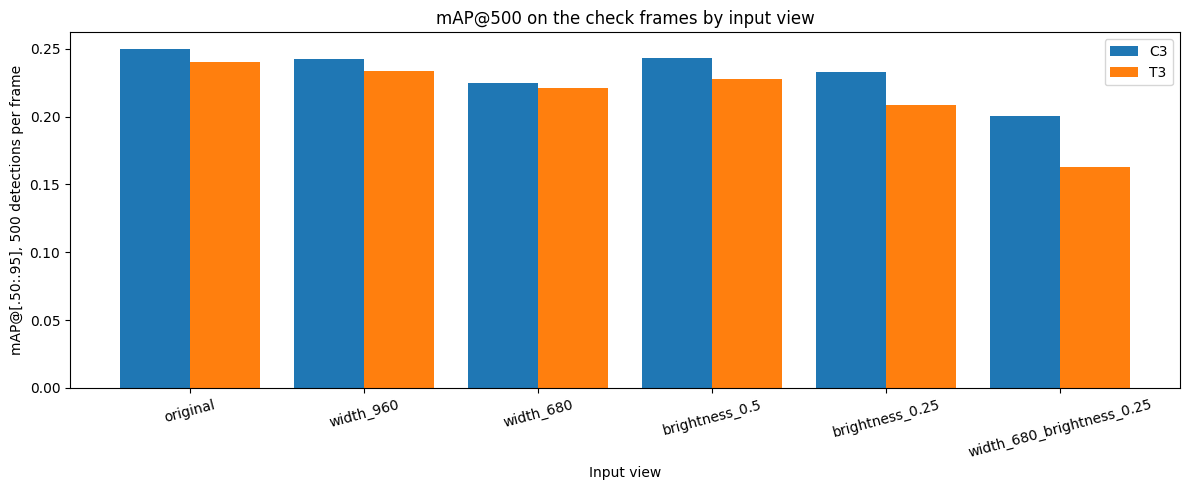

In [51]:
map_by_row = {
    (model_label, view_name): value
    for model_label, view_name, value in robustness.select("model", "view", "mAP").iter_rows()
}
positions = np.arange(len(evaluated_views))
bar_width = 0.8 / len(model_by_label)
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
for model_index, model_label in enumerate(model_by_label):
    ax.bar(
        positions + model_index * bar_width,
        [map_by_row[(model_label, view_name)] for view_name in evaluated_views],
        width=bar_width,
        label=model_label,
    )
ax.set_xticks(positions + bar_width * (len(model_by_label) - 1) / 2, evaluated_views, rotation=15)
ax.set_title("mAP@500 on the check frames by input view")
ax.set_xlabel("Input view")
ax.set_ylabel("mAP@[.50:.95], 500 detections per frame")
ax.legend()
save_figure(fig, "robustness", robustness.select("model", "view", "mAP", "AP_small", "delta_mAP_vs_original"))

## Inference views

The views of T3 that passed `SCOPE.md` §3.10 in P1 (flip at 1280, long sides 1600 and 1920, F101) are predicted with this run's best checkpoint on all val and all test frames, and saved as `view_c3_<view>_val_predictions.json` (COCO results format) and `view_c3_<view>_submission.csv` (submission format, top 500 per frame), so that X1 can fuse them as members without another inference notebook. They are not fused here, and `val_predictions.json` and `submission.csv` stay the plain view.

Helpers: `write_submission_file` writes a view's test detections with the same `format_prediction_string` as `submission.csv`, in `test_images.csv` order. `project_view_hours` estimates the hours of a view from the wall seconds per frame at 1280 px (first the full-val `ms_per_image` times `VIEW_OVERHEAD_FACTOR`, then the measured value of the last computed view divided by its pixel ratio), times the squared ratio of the long sides, times the val and test frames. T3's model from the robustness section is released first.

In [52]:
def write_submission_file(path: Path, detections_by_key: dict[str, FrameDetections]) -> None:
    view_prediction_by_image_id = {
        image_id: format_prediction_string(*detections_by_key[to_frame_key(file_name)])
        for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()
    }
    test_images.select("image_id").with_columns(
        PredictionString=pl.col("image_id").replace_strict(
            view_prediction_by_image_id, default="", return_dtype=pl.String
        )
    ).write_csv(path)


def compute_pixel_ratio(view: ViewSpec) -> float:
    return (view.size / IMAGE_SIZE) ** 2


def project_view_hours(view: ViewSpec, seconds_per_frame_at_base: float, frame_count: int) -> float:
    return seconds_per_frame_at_base * compute_pixel_ratio(view) * frame_count / 3600


del model_by_label, reference_model
torch.cuda.empty_cache()
val_paths = val_frames["path"].to_list()
test_paths = [str(DATA_ROOT / file_name) for file_name in test_images["file_name"]]
inference_views = [ViewSpec(is_flipped=True), *[ViewSpec(size=size) for size in INFERENCE_VIEW_SIZES]]
print(f"views {[view.name for view in inference_views]} | {len(val_paths)} val + {len(test_paths)} test frames")

views ['s1280_flip', 's1600', 's1920'] | 2846 val + 3811 test frames


The view loop. Before each view, the guard adds the projected hours of the view to the session clock and skips the view if the sum passes `SESSION_LIMIT_HOURS`. A computed view is predicted on val and test, both files are written, and its full-val COCOeval runs right away. One line per view.

In [53]:
inference_view_rows = []
seconds_per_frame_at_base = ms_per_image / 1000 * VIEW_OVERHEAD_FACTOR
for view in inference_views:
    stem = f"view_{VIEW_LABEL}_{view.name}"
    projected_hours = project_view_hours(view, seconds_per_frame_at_base, len(val_paths) + len(test_paths))
    if (time.time() - run_started) / 3600 + projected_hours > SESSION_LIMIT_HOURS:
        inference_view_rows.append({"view": view.name, "status": "skipped", "projected_hours": projected_hours})
        print(f"{view.name} | skipped: projected {projected_hours:.2f} h", flush=True)
        continue
    view_started = time.time()
    view_val_detections, view_ms_per_image = predict_view(model, val_paths, view)
    view_test_detections, _ = predict_view(model, test_paths, view)
    seconds_per_frame_at_base = (
        (time.time() - view_started) / (len(val_paths) + len(test_paths)) / compute_pixel_ratio(view)
    )
    view_val_predictions = to_coco_results(view_val_detections, val_image_id_by_key)
    (OUTPUT_DIR / f"{stem}_val_predictions.json").write_text(json.dumps(view_val_predictions))
    write_submission_file(OUTPUT_DIR / f"{stem}_submission.csv", view_test_detections)
    view_metrics = summarise_metrics(evaluate_coco(val_ground_truth, view_val_predictions))
    inference_view_rows.append(
        {
            "view": view.name,
            "status": "computed",
            "projected_hours": projected_hours,
            "hours": (time.time() - view_started) / 3600,
            "mAP": view_metrics["mAP"],
            "AP50": view_metrics["AP50"],
            "AP_small": view_metrics["AP_small"],
            "ms_per_image": view_ms_per_image,
            "val_file": f"{stem}_val_predictions.json",
            "submission_file": f"{stem}_submission.csv",
        }
    )
    del view_val_detections, view_test_detections, view_val_predictions
    print(
        f"{view.name} | mAP {view_metrics['mAP']:.4f} | AP_small {view_metrics['AP_small']:.4f} "
        f"| {view_ms_per_image:.1f} ms/image | session {(time.time() - run_started) / 3600:.2f} h",
        flush=True,
    )

s1280_flip | mAP 0.2425 | AP_small 0.1282 | 236.4 ms/image | session 4.25 h
s1600 | mAP 0.2411 | AP_small 0.1238 | 346.6 ms/image | session 4.97 h
s1920 | mAP 0.2289 | AP_small 0.1043 | 466.6 ms/image | session 5.91 h


Inference views table, written to `inference_views.csv`, with the plain view (the best checkpoint as evaluated in the Validation section) as the first row. How to read this table: one row per view; `status` is `computed` or `skipped` (by the session guard); `mAP`, `AP50` and `AP_small` are full-val metrics of that view alone at 500 detections per frame; `ms_per_image` follows `SPEED_PROTOCOL` with the preparation of the frame excluded; `projected_hours` and `hours` are the guard's estimate and the measured wall time of val and test prediction, files and COCOeval; the file columns name the saved outputs.

In [54]:
INFERENCE_VIEW_SCHEMA = {
    "view": pl.String,
    "status": pl.String,
    "projected_hours": pl.Float64,
    "hours": pl.Float64,
    "mAP": pl.Float64,
    "AP50": pl.Float64,
    "AP_small": pl.Float64,
    "ms_per_image": pl.Float64,
    "val_file": pl.String,
    "submission_file": pl.String,
}
plain_view_row = {
    "view": ViewSpec().name,
    "status": "computed",
    "mAP": val_metrics["mAP"],
    "AP50": val_metrics["AP50"],
    "AP_small": val_metrics["AP_small"],
    "ms_per_image": ms_per_image,
    "val_file": "val_predictions.json",
    "submission_file": "submission.csv",
}
inference_view_table = pl.DataFrame(
    [{name: row.get(name) for name in INFERENCE_VIEW_SCHEMA} for row in [plain_view_row, *inference_view_rows]],
    schema=INFERENCE_VIEW_SCHEMA,
).with_columns(pl.col("projected_hours", "hours").round(2), pl.col("ms_per_image").round(1))
inference_view_table.write_csv(OUTPUT_DIR / "inference_views.csv")
inference_view_table

view,status,projected_hours,hours,mAP,AP50,AP_small,ms_per_image,val_file,submission_file
str,str,f64,f64,f64,f64,f64,f64,str,str
"""s1280""","""computed""",null,null,0.2462,0.4934,0.1261,239.9,"""val_predictions.json""","""submission.csv"""
"""s1280_flip""","""computed""",0.53,0.52,0.2425,0.491,0.1282,236.4,"""view_c3_s1280_flip_val_predict…","""view_c3_s1280_flip_submission.…"
"""s1600""","""computed""",0.7,0.72,0.2411,0.4877,0.1238,346.6,"""view_c3_s1600_val_predictions.…","""view_c3_s1600_submission.csv"""
"""s1920""","""computed""",0.93,0.94,0.2289,0.4745,0.1043,466.6,"""view_c3_s1920_val_predictions.…","""view_c3_s1920_submission.csv"""


## References

- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497.
- Lin, Dollár, Girshick, He, Hariharan, Belongie. Feature Pyramid Networks for Object Detection. arXiv:1612.03144.
- Li, Xie, Lin, Wu, Girshick, He. Benchmarking Detection Transfer Learning with Vision Transformers (`v2` training recipe). arXiv:2111.11429.
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions, size buckets). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- Rezatofighi, Tsoi, Gwak, Sadeghian, Reid, Savarese. Generalized Intersection over Union: A Metric and a Loss for Bounding Box Regression. arXiv:1902.09630: the GIoU loss of the RoI head.
- Loshchilov, Hutter. SGDR: Stochastic Gradient Descent with Warm Restarts (cosine annealing, used without restarts). arXiv:1608.03983.
- Zhang, He, Zhang, Zhang, Xie, Li. Bag of Freebies for Training Object Detection Neural Networks (photometric augmentation for detectors). arXiv:1902.04103.
- Buslaev, Iglovikov, Khvedchenya, Parinov, Druzhinin, Kalinin. Albumentations: Fast and Flexible Image Augmentations (brightness, colour, downscale and JPEG-compression augmentations). arXiv:1809.06839.
- Singh, Davis. An Analysis of Scale Invariance in Object Detection – SNIP (input scale and small objects). arXiv:1711.08189.
- Solovyev, Wang, Gabruseva. Weighted Boxes Fusion: Ensembling Boxes from Different Object Detection Models (the fusion in X1 that consumes the saved views). arXiv:1910.13302.
- Bolya, Foley, Hays, Hoffman. TIDE: A General Toolbox for Identifying Object Detection Errors. arXiv:2008.08115: idea of splitting missed GT by attributes, as suggested in `EDA.md` §7.
- Ultralytics `hsv_h`, `hsv_s` and `hsv_v` augmentation arguments (source of the brightness, saturation and hue ranges; `RandomHSV` in `ultralytics/data/augment.py` of 8.4.193), AGPL-3.0: https://docs.ultralytics.com/usage/cfg/ and https://github.com/ultralytics/ultralytics
- torchvision `fasterrcnn_resnet50_fpn_v2` and detection reference scripts (optimiser, warmup, LR scaling), BSD-3-Clause: https://github.com/pytorch/vision/tree/main/references/detection
- torchvision Faster R-CNN model documentation: https://pytorch.org/vision/stable/models/faster_rcnn.html
- torchvision `RoIHeads`, `fastrcnn_loss`, `BoxCoder`, `AnchorGenerator`, `RegionProposalNetwork` and `GeneralizedRCNNTransform`, BSD-3-Clause: https://github.com/pytorch/vision/tree/main/torchvision/models/detection
- torchvision `generalized_box_iou_loss` (`torchvision.ops`), BSD-3-Clause: https://github.com/pytorch/vision/blob/main/torchvision/ops/giou_loss.py
- torchvision `encode_jpeg`, `decode_jpeg`, `decode_image` (`torchvision.io`) and `resize`, `adjust_saturation`, `adjust_hue` (`torchvision.transforms.v2.functional`), BSD-3-Clause: https://pytorch.org/vision/stable/io.html and https://pytorch.org/vision/stable/transforms.html
- PyTorch reproducibility notes (`seed_worker`, seeded generator) and `torch.utils.data.DataLoader` (per-epoch loader): https://pytorch.org/docs/stable/notes/randomness.html and https://pytorch.org/docs/stable/data.html
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§3.2 anchors and sizes, §5 clip resolutions, §7 occlusion and truncation, §8 temporal redundancy and frame step, §9 brightness): source of the size, resolution and brightness facts in the Overview and Config.
- Parent run T3 `faster-rcnn-giou` (`new-notebooks/faster-rcnn-giou.ipynb`, report `experiments/dmnk1304/faster-rcnn-giou.md`): the GIoU heads, the model build, the shared analysis cells, and `best.pt` (kernel source) for the robustness views.
- T11 `faster-rcnn-short-schedule` (`new-notebooks/faster-rcnn-short-schedule.ipynb`, report `experiments/draklowell/faster-rcnn-short-schedule.md`): the 6-epoch schedule and the final-epoch evaluation.
- P2 `pipeline-frame-offsets` (`new-notebooks/pipeline-frame-offsets.ipynb`, report `experiments/dmnk1304/pipeline-frame-offsets.md`): the rotating-offset split, the per-epoch loader and its training loop.
- P1 `pipeline-inference` (`new-notebooks/pipeline-inference.ipynb`, report `experiments/draklowell/pipeline-inference.md`): the view definition, the flip and scale views, the view file names and the NMS threshold selection.
- D1 `yolo11s-p2-robustness` (`new-notebooks/yolo11s-p2-robustness.ipynb`): the check frames, the robustness views and their tables.
- Base run T1 `faster-rcnn-small-anchors` (`new-notebooks/faster-rcnn-small-anchors.ipynb`): anchors 16–256 and the protocol code; legacy run `faster-cnn-5` (`notebooks/dmnk1304/faster-cnn-5.ipynb`): basis of `predict_rpn_proposals` and `rpn_recall.csv`.
- Findings F2, F17, F22, F55, F82, F83 and F98–F102 and decisions 15 and §8.4 of `SCOPE.md`, with the run numbers in `EXPERIMENTS.md`, quoted in the Overview and Config.